# Семинар 5. Тематические модели на практике

**Курс:** «Интеллектуальный анализ текстов: от статистических моделей языка до языковых агентов». Семинар относится к лекции 3 «Тематическое моделирование».

## Цель

Разобрать на примерах, как тематическая модель находит темы, и научиться строить, читать и оценивать такую модель. Каждый шаг сопровождается рисунком: сначала алгоритм виден на коллекции из шести коротких документов, затем применяется к 2000 новостей Lenta.ru и к данным о покупках клиентов банка.

## План занятия

| Часть | Содержание | Время |
|---|---|---|
| 1 | EM-алгоритм PLSA на учебной коллекции | 15 мин |
| 2 | Сэмплирование Гиббса на учебной коллекции | 10 мин |
| 3 | Распределение Дирихле и параметр $\alpha$ | 5 мин |
| 4 | Корпус новостей: предобработка и словарь | 10 мин |
| 5 | LSA как точка отсчёта | 5 мин |
| 6 | LDA: темы, доли тем в документах, карта коллекции | 20 мин |
| 7 | Качество: перплексия, когерентность, выбор числа тем | 15 мин |
| 8 | Регуляризация: разреживание тем | 5 мин |
| 9 | Данные без текста: транзакции клиентов банка | 10 мин |
| 10 | Задания для самостоятельной работы | дома |

Весь блокнот выполняется на процессоре за 5–6 минут. Дольше всего работают ячейки с обучением и оценкой LDA в частях 6 и 7.

## Обозначения

- $n_{dw}$ равно числу вхождений слова $w$ в документ $d$. Матрица $n_{dw}$ совпадает с мешком слов из лекции 2.
- $\phi_{wk}=p(w\mid k)$ обозначает вероятность слова $w$ в теме $k$. Матрица $\Phi$ хранит темы.
- $\theta_{kd}=p(k\mid d)$ обозначает долю темы $k$ в документе $d$. Матрица $\Theta$ хранит профили документов.
- $K$ обозначает число тем, $|W|$ размер словаря, $D$ число документов.

Модель объясняет частоты слов в документе смесью тем:

$$p(w\mid d)=\sum_{k=1}^{K}\phi_{wk}\,\theta_{kd}.$$

В коде матрица $\Phi$ хранится как массив `phi` размера $K\times|W|$ (строка задаёт тему), матрица $\Theta$ как массив `theta` размера $D\times K$ (строка задаёт документ).

In [1]:
import json
import random
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# одна палитра на весь блокнот: восемь цветов для тем и один синий ряд для тепловых карт
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MUTED, GRID = "#6b7280", "#e5e7eb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f6f9fe", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
print("Готово. SEED =", SEED)

Готово. SEED = 42


## Часть 1. EM-алгоритм PLSA на учебной коллекции

Учебная коллекция состоит из шести документов по шесть слов. В двух документах речь идёт о спорте, в двух о финансах, два документа смешанные. Тем две, и результат можно проверить глазами.

EM-алгоритм чередует два шага.

**E-шаг.** Для каждой пары (документ, слово) вычисляется вероятность того, что слово порождено темой $k$:

$$p(k\mid d,w)=\frac{\phi_{wk}\theta_{kd}}{\sum_{s}\phi_{ws}\theta_{sd}}.$$

**M-шаг.** Вхождения слов делятся между темами в этих пропорциях, и параметры пересчитываются как частоты:

$$n_{wk}=\sum_d n_{dw}\,p(k\mid d,w),\quad \phi_{wk}=\frac{n_{wk}}{\sum_v n_{vk}},\qquad n_{kd}=\sum_w n_{dw}\,p(k\mid d,w),\quad \theta_{kd}=\frac{n_{kd}}{\sum_s n_{sd}}.$$

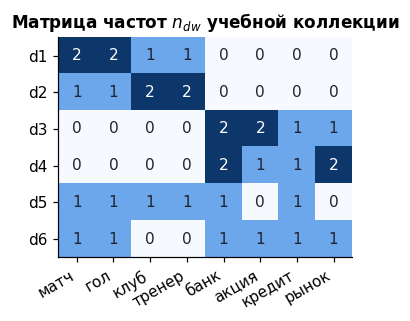

In [2]:
TOY = ["матч гол клуб тренер гол матч",
       "клуб тренер матч гол тренер клуб",
       "банк акция кредит рынок банк акция",
       "рынок банк кредит акция банк рынок",
       "матч гол клуб банк кредит тренер",
       "акция банк матч рынок гол кредит"]
toy_docs = [t.split() for t in TOY]
toy_vocab = ["матч", "гол", "клуб", "тренер", "банк", "акция", "кредит", "рынок"]
w2i = {w: i for i, w in enumerate(toy_vocab)}

N_toy = np.zeros((len(toy_docs), len(toy_vocab)))
for d, doc in enumerate(toy_docs):
    for w in doc:
        N_toy[d, w2i[w]] += 1

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.imshow(N_toy, cmap=SEQ, vmin=0)
ax.set_xticks(range(len(toy_vocab))); ax.set_xticklabels(toy_vocab, rotation=30, ha="right")
ax.set_yticks(range(len(toy_docs))); ax.set_yticklabels([f"d{i + 1}" for i in range(len(toy_docs))])
for d in range(N_toy.shape[0]):
    for w in range(N_toy.shape[1]):
        ax.text(w, d, int(N_toy[d, w]), ha="center", va="center", color="white" if N_toy[d, w] > 1 else "#1f2430")
ax.set_title("Матрица частот $n_{dw}$ учебной коллекции")
plt.show()

In [3]:
def plsa_em(N, K, n_iter=30, seed=0):
    # EM-алгоритм PLSA на плотной матрице N (документы x слова).
    # Возвращает историю: список (phi, theta, loglik) по итерациям.
    rng = np.random.RandomState(seed)
    D, W = N.shape
    phi = rng.rand(K, W) + 0.1
    phi /= phi.sum(1, keepdims=True)
    theta = rng.rand(D, K) + 0.1
    theta /= theta.sum(1, keepdims=True)
    history = []
    for it in range(n_iter + 1):
        p_dw = theta @ phi                                   # p(w|d), размер D x W
        loglik = float((N * np.log(p_dw + 1e-12)).sum())
        history.append((phi.copy(), theta.copy(), loglik))
        # E-шаг: p(k|d,w) = phi[k,w] * theta[d,k] / p(w|d), размер D x K x W
        p_kdw = theta[:, :, None] * phi[None, :, :] / (p_dw[:, None, :] + 1e-12)
        # M-шаг: делим вхождения слов между темами и пересчитываем частоты
        n_dkw = N[:, None, :] * p_kdw
        n_kw = n_dkw.sum(0)
        n_dk = n_dkw.sum(2)
        phi = n_kw / n_kw.sum(1, keepdims=True)
        theta = n_dk / n_dk.sum(1, keepdims=True)
    return history


toy_hist = plsa_em(N_toy, K=2, n_iter=30, seed=1)
print("log-правдоподобие: итерация 0: %.2f, итерация 1: %.2f, итерация 30: %.2f"
      % (toy_hist[0][2], toy_hist[1][2], toy_hist[30][2]))

log-правдоподобие: итерация 0: -77.84, итерация 1: -74.07, итерация 30: -57.12


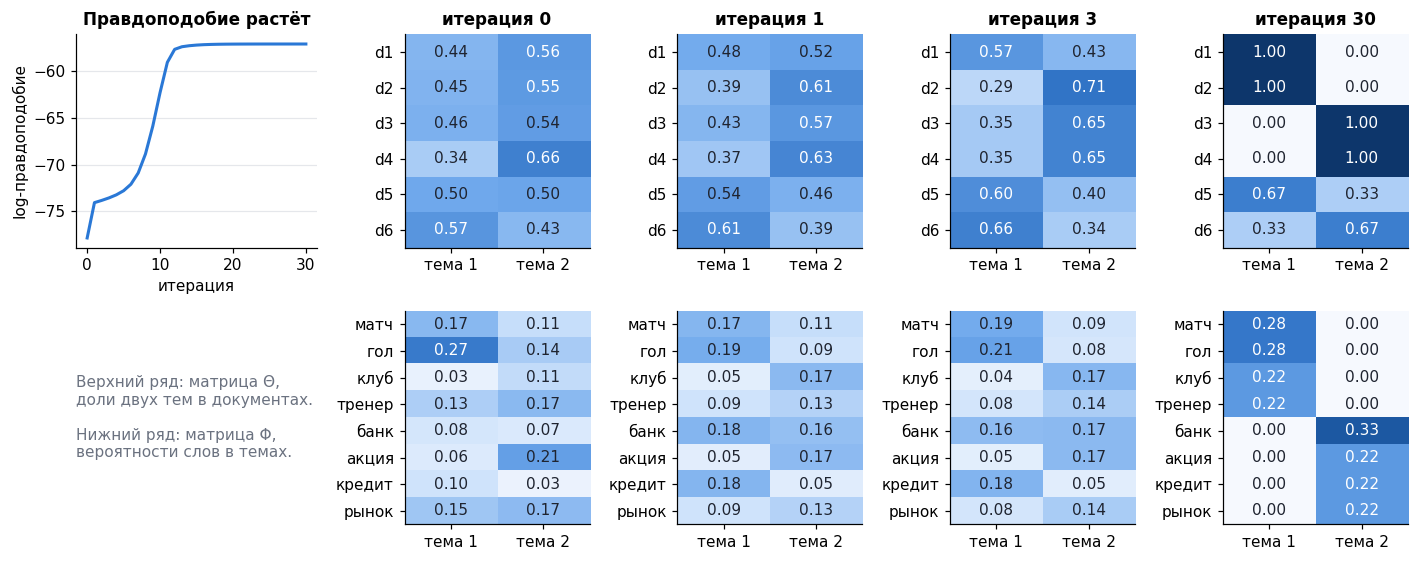

In [4]:
steps = [0, 1, 3, 30]
fig, axes = plt.subplots(2, len(steps) + 1, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3] + [1] * len(steps)})

ax = axes[0, 0]
ax.plot([h[2] for h in toy_hist], color=CAT[0], lw=2)
ax.set_xlabel("итерация"); ax.set_ylabel("log-правдоподобие"); ax.set_title("Правдоподобие растёт")
ax.grid(axis="y", color=GRID)
axes[1, 0].axis("off")
axes[1, 0].text(0, 0.5, "Верхний ряд: матрица Θ,\nдоли двух тем в документах.\n\nНижний ряд: матрица Φ,\nвероятности слов в темах.",
                va="center", fontsize=10, color=MUTED)

for j, it in enumerate(steps, start=1):
    phi, theta, _ = toy_hist[it]
    ax = axes[0, j]
    ax.imshow(theta, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    ax.set_title(f"итерация {it}")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["тема 1", "тема 2"])
    ax.set_yticks(range(6)); ax.set_yticklabels([f"d{i + 1}" for i in range(6)])
    for d in range(6):
        for k in range(2):
            ax.text(k, d, f"{theta[d, k]:.2f}", ha="center", va="center", color="white" if theta[d, k] > 0.55 else "#1f2430")
    ax = axes[1, j]
    ax.imshow(phi.T, cmap=SEQ, vmin=0, vmax=0.4, aspect="auto")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["тема 1", "тема 2"])
    ax.set_yticks(range(len(toy_vocab))); ax.set_yticklabels(toy_vocab)
    for w in range(len(toy_vocab)):
        for k in range(2):
            ax.text(k, w, f"{phi[k, w]:.2f}", ha="center", va="center", color="white" if phi[k, w] > 0.22 else "#1f2430")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** На итерации 0 параметры случайны, и обе темы содержат все слова примерно поровну. Уже через несколько итераций одна тема собирает слова «матч», «гол», «клуб», «тренер», вторая собирает «банк», «акция», «кредит», «рынок». Документы $d_1$–$d_4$ почти целиком относятся к одной теме, документы $d_5$ и $d_6$ делятся между двумя. Разметки не было: темы возникли только из того, какие слова встречаются в одних документах.

Номера тем условны. При другом значении `seed` спортивной может оказаться тема 2. Это свойство всех тематических моделей: модель находит темы, порядок и названия тем остаются за исследователем.

## Часть 2. Сэмплирование Гиббса на учебной коллекции

Сэмплирование Гиббса обучает модель LDA иначе. Каждому слову коллекции назначена тема, вначале случайная. Алгоритм проходит по словам, снимает назначение текущего слова и выбирает тему заново с вероятностью

$$p(z=k\mid\text{остальные назначения})\;\propto\;(n_{dk}+\alpha)\cdot\frac{n_{kw}+\beta}{n_k+|W|\beta}.$$

Здесь $n_{dk}$ равно числу слов документа $d$, отнесённых к теме $k$, $n_{kw}$ равно числу назначений слова $w$ теме $k$ во всей коллекции, $n_k$ равно общему числу слов темы $k$. Счётчики берутся без текущего слова. Первый множитель велик, если тема уже представлена в документе. Второй множитель велик, если слово уже встречалось в этой теме.

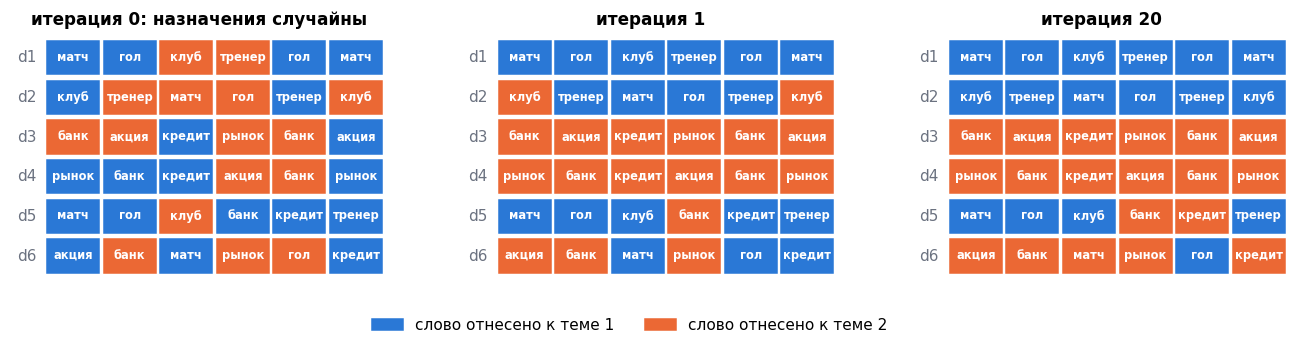

Доля темы 1 в документах после 20 проходов: [0.93 0.93 0.07 0.07 0.64 0.21]


In [5]:
def gibbs_lda(docs, vocab, K=2, alpha=0.5, beta=0.1, n_iter=20, seed=3, snapshots=(0, 1, 20)):
    # Коллапсированный сэмплер Гиббса для LDA. Возвращает снимки назначений тем и счётчики.
    rng = np.random.RandomState(seed)
    w2i = {w: i for i, w in enumerate(vocab)}
    V = len(vocab)
    z = [[rng.randint(K) for _ in doc] for doc in docs]            # случайные начальные назначения
    n_dk = np.zeros((len(docs), K)); n_kw = np.zeros((K, V)); n_k = np.zeros(K)
    for d, doc in enumerate(docs):
        for n, w in enumerate(doc):
            k = z[d][n]; n_dk[d, k] += 1; n_kw[k, w2i[w]] += 1; n_k[k] += 1
    snaps = {0: [list(x) for x in z]}
    for it in range(1, n_iter + 1):
        for d, doc in enumerate(docs):
            for n, w in enumerate(doc):
                k, v = z[d][n], w2i[w]
                n_dk[d, k] -= 1; n_kw[k, v] -= 1; n_k[k] -= 1          # снимаем назначение текущего слова
                p = (n_dk[d] + alpha) * (n_kw[:, v] + beta) / (n_k + V * beta)
                k = rng.choice(K, p=p / p.sum())                        # выбираем тему заново
                z[d][n] = k
                n_dk[d, k] += 1; n_kw[k, v] += 1; n_k[k] += 1
        if it in snapshots:
            snaps[it] = [list(x) for x in z]
    return snaps, n_dk, n_kw


snaps, n_dk, n_kw = gibbs_lda(toy_docs, toy_vocab)
sport = int(n_kw[:, toy_vocab.index("матч")].argmax())   # тема со словом «матч» рисуется синим

fig, axes = plt.subplots(1, 3, figsize=(15, 2.9))
for ax, it in zip(axes, sorted(snaps)):
    for r, doc in enumerate(toy_docs):
        for c, w in enumerate(doc):
            col = CAT[0] if snaps[it][r][c] == sport else CAT[1]
            ax.add_patch(plt.Rectangle((c + 0.04, -r - 0.42), 0.92, 0.84, color=col))
            ax.text(c + 0.5, -r, w, ha="center", va="center", color="white", fontsize=7.5, fontweight="bold")
        ax.text(-0.15, -r, f"d{r + 1}", ha="right", va="center", color=MUTED)
    ax.set_xlim(-0.6, 6.05); ax.set_ylim(-5.6, 0.6); ax.axis("off")
    ax.set_title("итерация 0: назначения случайны" if it == 0 else f"итерация {it}")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=CAT[0]), plt.Rectangle((0, 0), 1, 1, color=CAT[1])],
           ["слово отнесено к теме 1", "слово отнесено к теме 2"], ncol=2, loc="lower center", frameon=False,
           bbox_to_anchor=(0.5, -0.1))
plt.show()

alpha_toy = 0.5
theta_gibbs = (n_dk + alpha_toy) / (n_dk + alpha_toy).sum(1, keepdims=True)
print("Доля темы 1 в документах после 20 проходов:", np.round(theta_gibbs[:, sport], 2))

**Что видно на рисунке.** Вначале цвета перемешаны. После 20 проходов спортивные слова получили один цвет, финансовые другой. В смешанных документах $d_5$ и $d_6$ остались оба цвета. Оценки долей тем получаются из счётчиков: $\hat\theta_{kd}=(n_{dk}+\alpha)/(n_d+K\alpha)$.

EM-алгоритм из части 1 делит каждое слово между темами дробно и детерминированно. Сэмплер Гиббса относит каждое слово к одной теме целиком и делает это случайно, поэтому два запуска с разными `seed` дают немного разные назначения. Собственный сэмплер Гиббса для полноценного корпуса реализуется в домашнем задании 1.

## Часть 3. Распределение Дирихле и параметр $\alpha$

В модели LDA вектор долей тем документа считается случайным: $\theta_d\sim\mathrm{Dir}(\alpha)$. Параметр $\alpha$ задаёт, какие документы модель ожидает увидеть. Ниже для трёх значений $\alpha$ сгенерировано по пять случайных документов при восьми темах.

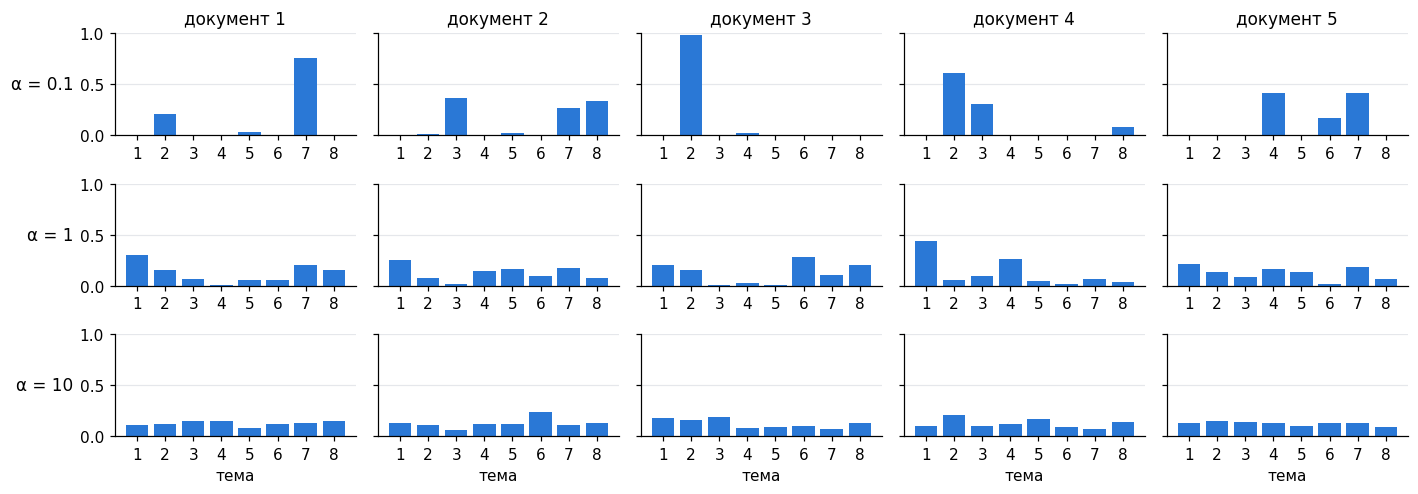

In [6]:
rng = np.random.RandomState(SEED)
K_demo = 8
fig, axes = plt.subplots(3, 5, figsize=(13, 4.6), sharey=True)
for r, a in enumerate([0.1, 1.0, 10.0]):
    for c in range(5):
        ax = axes[r, c]
        ax.bar(range(1, K_demo + 1), rng.dirichlet([a] * K_demo), color=CAT[0])
        ax.set_ylim(0, 1); ax.set_xticks(range(1, K_demo + 1)); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
        if c == 0:
            ax.set_ylabel(f"α = {a:g}", rotation=0, ha="right", va="center", fontsize=11)
        if r == 0:
            ax.set_title(f"документ {c + 1}", fontweight="normal")
        if r == 2:
            ax.set_xlabel("тема")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** При $\alpha=0.1$ в документе заметны одна-две темы, остальные близки к нулю. При $\alpha=10$ все темы представлены почти поровну, и документы не отличаются друг от друга. Реальные тексты похожи на верхний ряд, поэтому для них берут $\alpha<1$. В библиотеке gensim значение `alpha="auto"` подбирает $\alpha$ по данным в ходе обучения.

Параметр $\beta$ действует так же на распределение слов в теме: при малом $\beta$ тема сосредоточена на небольшом наборе слов. В формуле Гиббса $\beta$ играет роль добавки из сглаживания Лапласа (лекция 1).

## Часть 4. Корпус новостей: предобработка и словарь

Основной корпус семинара состоит из 2000 новостей Lenta.ru. Файл `data/lenta_ru_2000.jsonl` создаётся на семинаре 0. Если файла нет, тексты загружаются с HuggingFace Hub. У каждой новости есть редакционная рубрика. В обучении она не участвует и понадобится позже для проверки тем.

Загружено 2000 новостей, источник: локальный файл lenta_ru_2000.jsonl
Пример: Два немца стали кандидатами в тренеры "Динамо" | Два немецких футбольных тренера стали кандидатами на пост нового наставника московского "Динамо". В качестве основного рассматривается кандидатура Феликса Магат ...


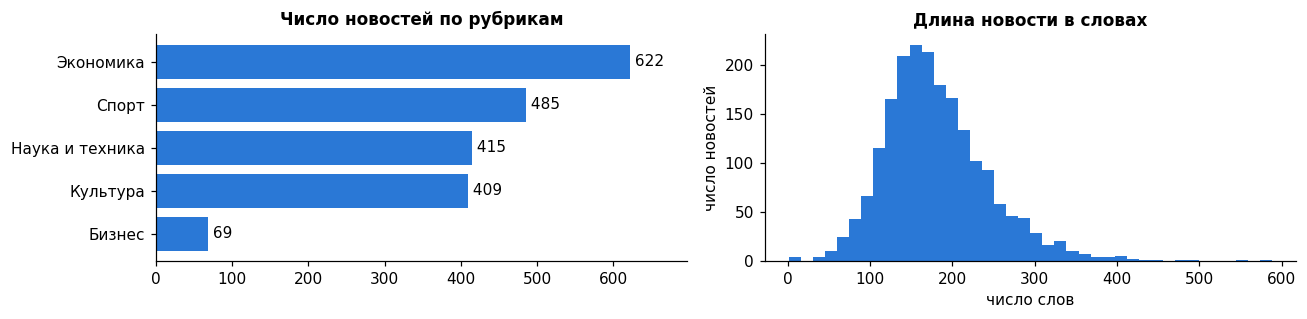

In [7]:
def load_lenta(n_docs=2000):
    # 1) локальный кэш семинара 0: каталог data в корне курса ищется вверх по дереву
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        f = parent / "data" / "lenta_ru_2000.jsonl"
        if f.exists():
            rows = [json.loads(line) for line in open(f, encoding="utf-8")][:n_docs]
            return rows, f"локальный файл {f.name}"
    # 2) загрузка с HuggingFace Hub тем же способом, что в семинаре 0
    from datasets import load_dataset
    rows = []
    for row in load_dataset("zloelias/lenta-ru", split="train", streaming=True):
        rows.append({"title": row["title"], "text": row["text"] or "", "topic": row["topic"]})
        if len(rows) >= n_docs:
            break
    return rows, "HuggingFace Hub: zloelias/lenta-ru"


rows, source = load_lenta()
titles = [r["title"].replace("\xa0", " ").strip() for r in rows]
texts = [r["text"] for r in rows]
rubrics = np.array([r["topic"] for r in rows])
print(f"Загружено {len(rows)} новостей, источник: {source}")
print("Пример:", titles[0], "|", texts[0][:160], "...")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
cnt = pd.Series(rubrics).value_counts()
axes[0].barh(cnt.index[::-1], cnt.values[::-1], color=CAT[0])
for i, v in enumerate(cnt.values[::-1]):
    axes[0].text(v, i, f" {v}", va="center")
axes[0].set_title("Число новостей по рубрикам"); axes[0].set_xlim(0, cnt.max() * 1.12)
lens = [len(t.split()) for t in texts]
axes[1].hist(lens, bins=40, color=CAT[0])
axes[1].set_title("Длина новости в словах"); axes[1].set_xlabel("число слов"); axes[1].set_ylabel("число новостей")
fig.tight_layout()
plt.show()

### Предобработка

Тематическая модель работает с мешком слов, поэтому качество тем зависит от того, что считается словом. Предобработка состоит из трёх шагов.

1. **Токенизация.** Из текста выделяются слова, записанные кириллицей.
2. **Лемматизация.** Каждое слово приводится к начальной форме библиотекой `pymorphy3`. Без этого шага «банк», «банка» и «банком» остаются тремя разными словами, и статистика по ним дробится.
3. **Удаление стоп-слов.** Служебные слова и общая новостная лексика («сообщить», «заявить», «год») встречаются во всех темах и ничего о теме не сообщают.

In [8]:
import pymorphy3

try:
    from nltk.corpus import stopwords
    STOP = set(stopwords.words("russian"))
except Exception:
    # запасной список на случай, когда словари nltk не загружены
    STOP = set("и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было "
               "вот от меня еще нет о из ему теперь когда даже ну ли если уже или ни быть был него до вас там потом "
               "себя ничего ей может они тут где есть надо ней для мы тебя их чем была сам без будто чего раз тоже "
               "себе под будет тогда кто этот того потому этого какой ним здесь этом один мой тем чтобы нее были куда "
               "всех можно при два об другой после над больше тот через эти нас про всего них какая много три эту "
               "перед лучше том такой им более всегда между".split())

# общая новостная лексика, найденная при чтении первых вариантов тем
EXTRA_STOP = set('''это который весь свой год также мочь такой наш ещё однако кроме время сообщать сообщить заявить
заявлять отметить отмечать рассказать слово данные сообщение являться стать один два три первый второй новый самый
другой около более менее несколько январь февраль март апрель май июнь июль август сентябрь октябрь ноябрь декабрь
понедельник вторник среда четверг пятница суббота воскресенье lenta риа новость интерфакс итар тасс человек день неделя
месяц число процент миллион миллиард тысяча рубль доллар получить составить сказать говорить считать пока лишь например
именно ранее должный очень иметь находиться какой либо любой каждый результат часть случай место раз решение сторона
работа мир'''.split())
STOP |= EXTRA_STOP

morph = pymorphy3.MorphAnalyzer()
token_re = re.compile(r"[а-яё]+")
_lemma_cache = {}


def preprocess(text, lemmatize=True):
    out = []
    for t in token_re.findall(text.lower()):
        if len(t) < 3:
            continue
        if lemmatize:
            if t not in _lemma_cache:
                _lemma_cache[t] = morph.parse(t)[0].normal_form
            lemma = _lemma_cache[t]
        else:
            lemma = t
        lemma = lemma.replace("ё", "е")
        if lemma not in STOP and t not in STOP:
            out.append(lemma)
    return out


docs = [preprocess(title + ". " + text) for title, text in zip(titles, texts)]
print("Исходный текст:", texts[0][:150])
print("После предобработки:", docs[0][:16])
print(f"Всего слов в корпусе: {sum(map(len, docs))}, разных слов: {len(set(w for d in docs for w in d))}")

Исходный текст: Два немецких футбольных тренера стали кандидатами на пост нового наставника московского "Динамо". В качестве основного рассматривается кандидатура Фел
После предобработки: ['немец', 'кандидат', 'тренер', 'динамо', 'немецкий', 'футбольный', 'тренер', 'кандидат', 'пост', 'наставник', 'московский', 'динамо', 'качество', 'основный', 'рассматриваться', 'кандидатура']
Всего слов в корпусе: 218404, разных слов: 22068


### Разбиение и словарь

Корпус делится на обучающую часть (1700 документов) и отложенную (300 документов). Отложенные документы не участвуют ни в построении словаря, ни в обучении: на них проверяется, как модель описывает новые тексты.

Из словаря убираются два вида слов. Слово, которое встретилось менее чем в 5 документах, не даёт статистики совместной встречаемости. Слово, которое встретилось более чем в 30 % документов, присутствует во всех темах.

Словарь: 20416 слов до фильтрации, 4674 после


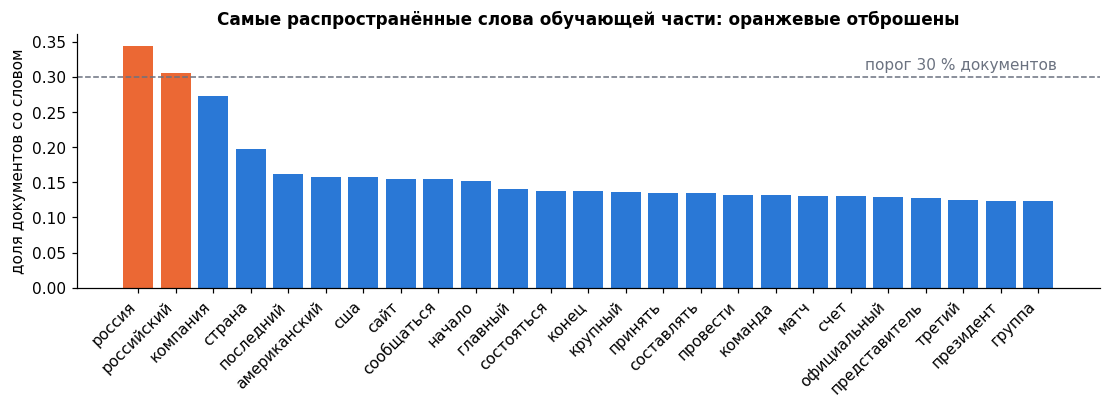

In [9]:
from gensim.corpora import Dictionary
from gensim.matutils import corpus2csc

idx = list(range(len(docs)))
random.Random(SEED).shuffle(idx)
train_idx, test_idx = idx[:1700], idx[1700:]
train_docs = [docs[i] for i in train_idx]
test_docs = [docs[i] for i in test_idx]

dictionary = Dictionary(train_docs)
size_before = len(dictionary)
df_before = {dictionary[i]: n / len(train_docs) for i, n in dictionary.dfs.items()}
dictionary.filter_extremes(no_below=5, no_above=0.3)
train_bow = [dictionary.doc2bow(d) for d in train_docs]
test_bow = [dictionary.doc2bow(d) for d in test_docs]
print(f"Словарь: {size_before} слов до фильтрации, {len(dictionary)} после")

top = sorted(df_before.items(), key=lambda t: -t[1])[:25]
fig, ax = plt.subplots(figsize=(12, 3))
cols = [CAT[1] if p > 0.3 else CAT[0] for _, p in top]
ax.bar([w for w, _ in top], [p for _, p in top], color=cols)
ax.axhline(0.3, color=MUTED, ls="--", lw=1)
ax.text(len(top) - 0.5, 0.31, "порог 30 % документов", ha="right", color=MUTED)
ax.set_ylabel("доля документов со словом")
ax.set_title("Самые распространённые слова обучающей части: оранжевые отброшены")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

## Часть 5. LSA как точка отсчёта

Латентно-семантический анализ применяет усечённое сингулярное разложение (SVD) к матрице TF-IDF. Это самый простой способ найти скрытые направления в коллекции, и с ним удобно сравнивать вероятностные модели.

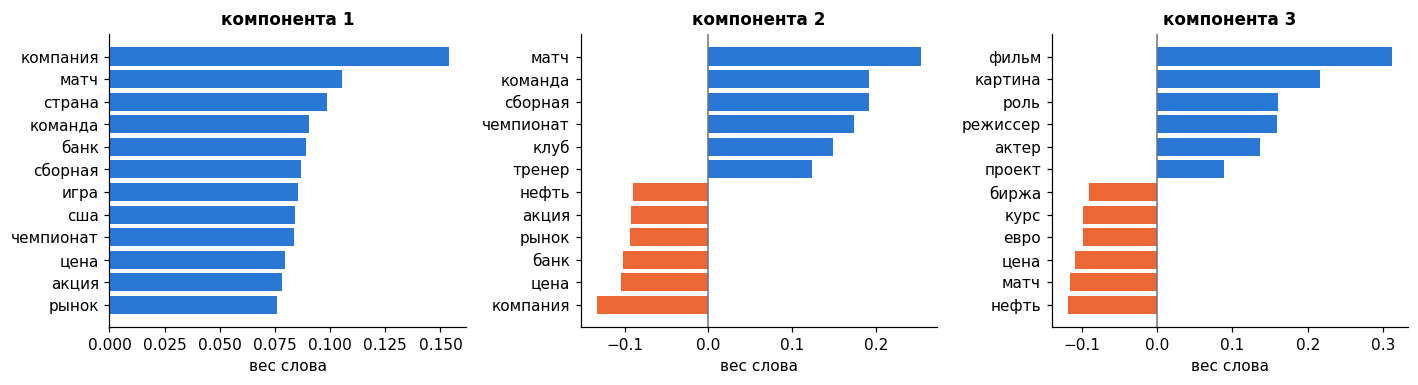

In [10]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfTransformer

N_train = corpus2csc(train_bow, num_terms=len(dictionary)).T.tocsr()     # документы x слова
N_test = corpus2csc(test_bow, num_terms=len(dictionary)).T.tocsr()
X_tfidf = TfidfTransformer(sublinear_tf=True).fit_transform(N_train)
svd = TruncatedSVD(n_components=4, random_state=SEED).fit(X_tfidf)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, range(3)):
    comp = svd.components_[c] * (1 if svd.components_[c].sum() > 0 or c > 0 else -1)
    sel = set(np.argsort(comp)[::-1][:6]) | (set(np.argsort(comp)[:6]) if c > 0 else set(np.argsort(comp)[::-1][:12]))
    sel = sorted(sel, key=lambda i: comp[i])
    ax.barh([dictionary[i] for i in sel], comp[sel], color=[CAT[0] if comp[i] > 0 else CAT[1] for i in sel])
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title(f"компонента {c + 1}"); ax.set_xlabel("вес слова")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** Первая компонента собирает самые частые слова коллекции. Во второй и третьей компонентах слова делятся на две группы с весами разных знаков: одна компонента описывает сразу две темы. Отрицательный вес нельзя прочитать как вероятность, и долю «темы» в документе по такому разложению определить нельзя. Вероятностные модели устраняют оба недостатка: их параметры неотрицательны и в сумме дают единицу.

## Часть 6. LDA на новостях

Модель обучается библиотекой gensim. Основные параметры:

- `num_topics` задаёт число тем $K$. Здесь взято $K=8$, выбор обсуждается в части 7.
- `passes` задаёт число проходов по корпусу, `chunksize` число документов в одной порции. Параметры модели обновляются после каждой порции, поэтому при порциях по 500 документов модель за один проход уточняется несколько раз и сходится быстрее.
- `alpha="auto"`, `eta="auto"` включают подбор параметров распределений Дирихле по данным. В gensim параметр $\beta$ называется `eta`.
- `random_state` фиксирует инициализацию. Вариационный вывод зависит от начального приближения, поэтому значение `seed` влияет на темы. Ниже модель обучается шесть раз с разными значениями.

In [11]:
from gensim.models import CoherenceModel, LdaModel


def train_lda(k, seed=SEED, passes=20, corpus=None, id2word=None):
    return LdaModel(corpus=train_bow if corpus is None else corpus, id2word=id2word or dictionary, num_topics=k,
                    random_state=seed, passes=passes, chunksize=500, iterations=100, alpha="auto", eta="auto")


def get_phi(model):
    phi = model.get_topics()                       # K x |W|
    return phi / phi.sum(1, keepdims=True)


def get_theta(model, corpus):
    theta = np.zeros((len(corpus), model.num_topics))
    for i, bow in enumerate(corpus):
        for k, p in model.get_document_topics(bow, minimum_probability=0):
            theta[i, k] = p
    return theta


def top_words(phi, k, n=10, id2word=None):
    id2word = id2word or dictionary
    return [id2word[i] for i in np.argsort(phi[k])[::-1][:n]]


def model_coherence(model, measure="c_npmi"):
    ph = get_phi(model)
    topics = [top_words(ph, k) for k in range(model.num_topics)]
    return CoherenceModel(topics=topics, texts=train_docs, dictionary=dictionary, coherence=measure, topn=10).get_coherence()


K_MAIN = 8
SEEDS = (1, 2, 3, 4, 5, 6)
candidates = {s: train_lda(K_MAIN, seed=s) for s in SEEDS}
cand_cv = {s: model_coherence(m) for s, m in candidates.items()}
for s in SEEDS:
    print(f"seed={s}: когерентность NPMI = {cand_cv[s]:.3f}")
best_seed = max(cand_cv, key=cand_cv.get)
lda = candidates[best_seed]
phi = get_phi(lda)
theta = get_theta(lda, train_bow)
print(f"\nВыбран запуск seed={best_seed}. Темы этой модели:")
for k in range(K_MAIN):
    print(f"Тема {k + 1}:", ", ".join(top_words(phi, k)))

seed=1: когерентность NPMI = 0.064
seed=2: когерентность NPMI = 0.040
seed=3: когерентность NPMI = 0.071
seed=4: когерентность NPMI = 0.080
seed=5: когерентность NPMI = 0.088
seed=6: когерентность NPMI = 0.080

Выбран запуск seed=5. Темы этой модели:
Тема 1: игра, группа, песня, концерт, выйти, альбом, турнир, третий, сайт, рейтинг
Тема 2: фильм, картина, роль, хороший, премия, актер, режиссер, главный, американский, театр
Тема 3: банк, страна, украина, финансовый, министр, президент, правительство, организация, глава, средство
Тема 4: матч, сборная, команда, чемпионат, клуб, счет, тренер, игра, победа, чемпион
Тема 5: компания, акция, самолет, предприятие, контракт, сделка, проект, производство, военный, крупный
Тема 6: ученый, ракета, система, космический, исследование, корабль, сша, аппарат, обнаружить, спутник
Тема 7: цена, нефть, рынок, рост, газ, курс, компания, стоимость, биржа, баррель
Тема 8: компания, суд, сеть, дело, газета, писать, представитель, московский, москва, право


**Почему запусков несколько.** Обучение начинается со случайного приближения и сходится к разным решениям. Когерентность запусков различается: в неудачном запуске в одну тему попадают слова из разных предметов. Поэтому модель обучают несколько раз и берут запуск с наибольшей когерентностью. Когерентность NPMI измеряет смысловую связность главных слов темы, её определение дано в части 7.

### Темы как распределения на словах

Строка матрицы $\Phi$ задаёт тему. На рисунке показаны восемь самых вероятных слов каждой темы и их вероятности.

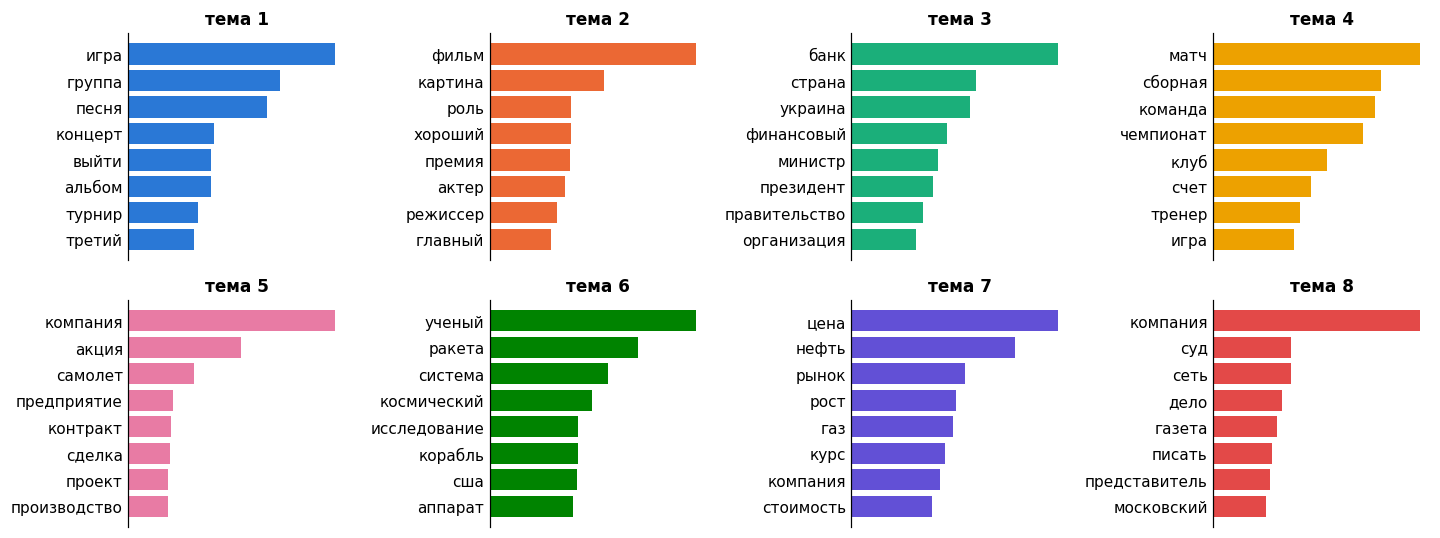

In [12]:
def plot_topics(phi, n_words=8, ncols=4, id2word=None, names=None):
    id2word = id2word or dictionary
    K = phi.shape[0]
    nrows = int(np.ceil(K / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 2.5 * nrows))
    for k, ax in enumerate(np.atleast_1d(axes).ravel()):
        if k >= K:
            ax.axis("off"); continue
        order = np.argsort(phi[k])[::-1][:n_words][::-1]
        ax.barh([id2word[i] for i in order], phi[k, order], color=CAT[k % len(CAT)])
        ax.set_title(names[k] if names else f"тема {k + 1}")
        ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
    fig.tight_layout()
    plt.show()


plot_topics(phi)

**Как читать рисунок.** Модель возвращает только распределения, и не все темы получаются одинаково удачными. Название теме даёт человек по её главным словам и по документам с наибольшей долей темы. Ниже для каждой темы выведены три таких документа. Темы, в которых слова и заголовки согласованы, получились удачными. Тема со словами из разных предметов означает, что модель слила два предмета в один: это повод изменить число тем или словарь.

In [13]:
train_titles = [titles[i] for i in train_idx]
train_rubrics = rubrics[train_idx]
for k in range(K_MAIN):
    best = np.argsort(theta[:, k])[::-1][:3]
    print(f"Тема {k + 1} ({', '.join(top_words(phi, k, 5))})")
    for i in best:
        print(f"    {theta[i, k]:.2f}  {train_titles[i]}")

Тема 1 (игра, группа, песня, концерт, выйти)
    0.92  Шарапова вышла в 1/4 финала на турнире в США
    0.89  В новом рейтинге WTA Курникова поднялась на семь строчек
    0.86  Джек Уайт записал сольный альбом
Тема 2 (фильм, картина, роль, хороший, премия)
    0.98  Хью Джекман снимется в новых "Людях Икс"
    0.95  Оскар 2006: "Кинг Конг" получил премию за лучший звук
    0.93  Студия Warner Bros. выпустила новый  ролик "Темного рыцаря"
Тема 3 (банк, страна, украина, финансовый, министр)
    0.99  Агентство Fitch вновь понизило долгосрочный рейтинг Украины
    0.99  Кудрин рассказал о предложенной ему Медведевым должности
    0.98  Еврокомиссия одобрила вступление Словакии в зону евро
Тема 4 (матч, сборная, команда, чемпионат, клуб)
    0.99  ЦСКА проиграл «Тоттенхэму» в последнем матче Слуцкого во главе команды
    0.98  "Арсенал" потерял основного защитника до конца сезона
    0.98  «Барыс» сократил отставание от «Салавата Юлаева» в Кубке Гагарина
Тема 5 (компания, акция, самолет, п

### Документы как смеси тем

Строка матрицы $\Theta$ задаёт профиль документа. Рисунок показывает профили восьми документов: четыре с одной преобладающей темой и четыре, в которых заметны две темы.

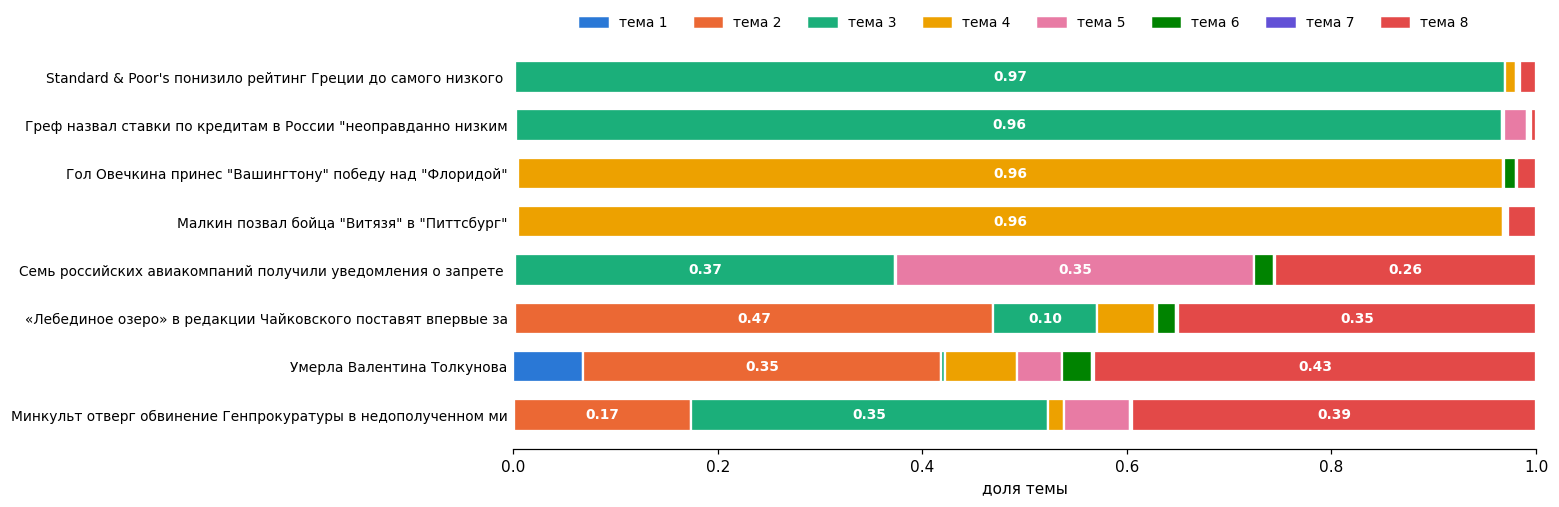

In [14]:
def plot_mixtures(theta_rows, labels, n_topics, title=None):
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(labels) + 1.2))
    for row, th in enumerate(theta_rows[::-1]):
        left = 0
        for k in range(n_topics):
            ax.barh(row, th[k], left=left, color=CAT[k % len(CAT)], edgecolor="white", linewidth=1.5, height=0.65)
            if th[k] > 0.08:
                ax.text(left + th[k] / 2, row, f"{th[k]:.2f}", ha="center", va="center", color="white", fontsize=9,
                        fontweight="bold")
            left += th[k]
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels[::-1], fontsize=9)
    ax.set_xlim(0, 1); ax.set_xlabel("доля темы"); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=CAT[k % len(CAT)]) for k in range(n_topics)],
              [f"тема {k + 1}" for k in range(n_topics)], ncol=n_topics, loc="lower center", bbox_to_anchor=(0.5, 1.0),
              frameon=False, fontsize=9)
    if title:
        ax.set_title(title, y=1.12)
    plt.show()


srt = np.sort(theta, axis=1)
long_enough = np.array([len(d) > 60 for d in train_docs])
pure = [i for i in np.argsort(-srt[:, -1]) if long_enough[i] and srt[i, -1] < 0.97][:4]
mixed = [i for i in np.argsort(np.abs(srt[:, -2] - 0.35)) if long_enough[i] and srt[i, -1] < 0.65][:4]
chosen = pure + mixed
plot_mixtures([theta[i] for i in chosen], [train_titles[i][:60] for i in chosen], K_MAIN)

### Тема каждого слова в документе

Модель позволяет оценить, какой теме принадлежит отдельное слово документа: $p(k\mid d,w)\propto\phi_{wk}\theta_{kd}$. Ниже слова одного из смешанных документов окрашены в цвет наиболее вероятной темы. Серым показаны слова, которых нет в словаре модели.

In [15]:
from IPython.display import HTML, display


def color_document(i, max_words=120):
    words = train_docs[i][:max_words]
    spans = []
    for w in words:
        if w in dictionary.token2id:
            k = int(np.argmax(phi[:, dictionary.token2id[w]] * theta[i]))
            spans.append(f'<span style="background:{CAT[k % len(CAT)]};color:white;padding:1px 4px;border-radius:3px;'
                         f'margin:1px;display:inline-block">{w}</span>')
        else:
            spans.append(f'<span style="color:#9aa0a6;margin:1px">{w}</span>')
    legend = " ".join(f'<span style="background:{CAT[k % len(CAT)]};color:white;padding:1px 6px;border-radius:3px">'
                      f'тема {k + 1}: {theta[i, k]:.2f}</span>' for k in np.argsort(-theta[i])[:3])
    display(HTML(f"<b>{train_titles[i]}</b><br>{legend}<br><div style='line-height:1.9'>{' '.join(spans)}</div>"))


color_document(mixed[0])

### Проверка по рубрикам

Редакционная рубрика в обучении не участвовала. Тепловая карта показывает среднюю долю каждой темы в документах каждой рубрики. Если темы осмысленны, у рубрики будет одна-две преобладающие темы.

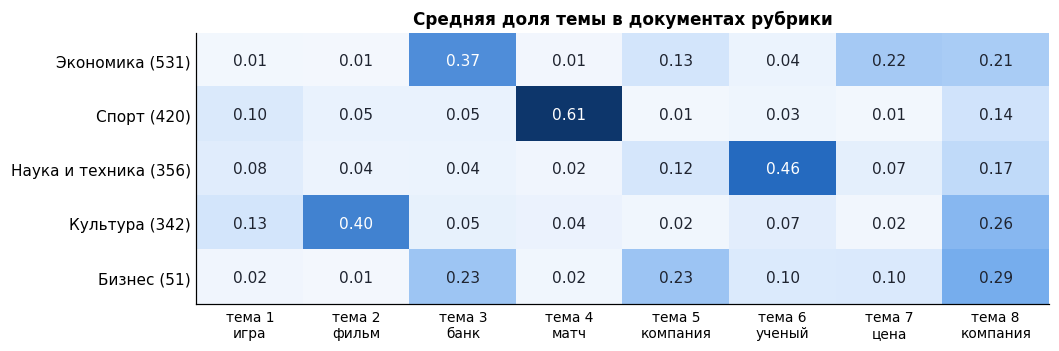

In [16]:
rub_names = [r for r in pd.Series(train_rubrics).value_counts().index]
M = np.array([theta[train_rubrics == r].mean(0) for r in rub_names])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(M, cmap=SEQ, vmin=0, aspect="auto")
ax.set_xticks(range(K_MAIN))
ax.set_xticklabels([f"тема {k + 1}\n{top_words(phi, k, 1)[0]}" for k in range(K_MAIN)], fontsize=9)
ax.set_yticks(range(len(rub_names))); ax.set_yticklabels([f"{r} ({(train_rubrics == r).sum()})" for r in rub_names])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] > 0.55 * M.max() else "#1f2430")
ax.set_title("Средняя доля темы в документах рубрики")
ax.tick_params(length=0)
plt.show()

**Что видно на рисунке.** Темы согласуются с рубриками и при этом делят их на более узкие предметы. Одна рубрика обычно распадается на две темы, например спорт на футбол и остальные виды. Некоторые темы собирают документы из разных рубрик: редакционное деление и статистика слов не обязаны совпадать.

### Карта коллекции

Профиль документа является точкой в $K$-мерном пространстве. Алгоритм t-SNE проецирует эти точки на плоскость с сохранением соседства. Цвет точки соответствует преобладающей теме документа.

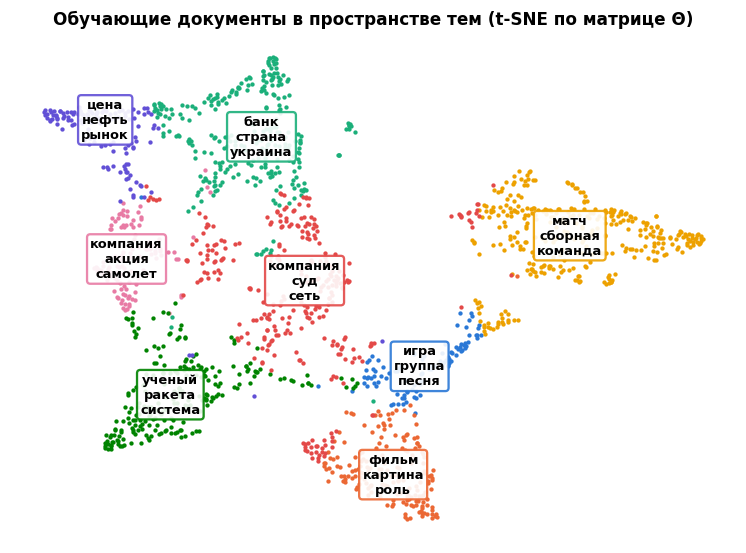

In [17]:
from sklearn.manifold import TSNE

xy = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(theta)
dominant = theta.argmax(1)
fig, ax = plt.subplots(figsize=(8.5, 6))
for k in range(K_MAIN):
    m = dominant == k
    ax.scatter(xy[m, 0], xy[m, 1], s=8, color=CAT[k], linewidth=0)
    cx, cy = np.median(xy[m], axis=0)
    ax.text(cx, cy, "\n".join(top_words(phi, k, 3)), ha="center", va="center", fontsize=8.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=CAT[k], lw=1.5, alpha=0.9))
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Обучающие документы в пространстве тем (t-SNE по матрице Θ)")
plt.show()

**Что видно на рисунке.** Документы с одной преобладающей темой образуют плотные группы. Точки между группами соответствуют документам, в которых смешаны две темы.

### Близость тем

Темы тоже можно сравнивать между собой. Расстояние Йенсена–Шеннона измеряет различие двух распределений на словах и принимает значения от 0 до 1. Слева показана матрица расстояний между темами, справа темы размещены на плоскости методом многомерного шкалирования. Площадь круга пропорциональна доле темы в коллекции. Так же устроена левая панель интерактивной визуализации pyLDAvis.

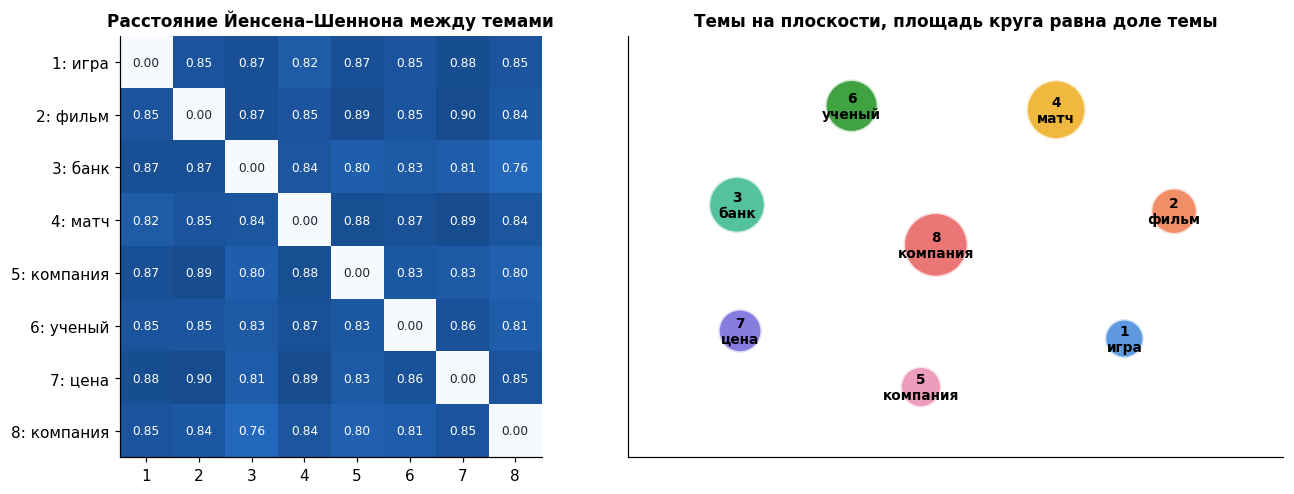

Самые близкие темы: 3 и 8, расстояние 0.76
    банк, страна, украина, финансовый, министр, президент, правительство, организация
    компания, суд, сеть, дело, газета, писать, представитель, московский


In [18]:
from scipy.spatial.distance import jensenshannon
from sklearn.manifold import MDS

dist = np.array([[jensenshannon(phi[a], phi[b], base=2) for b in range(K_MAIN)] for a in range(K_MAIN)])
share = theta.mean(0)
pos = MDS(n_components=2, dissimilarity="precomputed", random_state=SEED).fit_transform(dist)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
ax.imshow(dist, cmap=SEQ, vmin=0, vmax=1)
ax.set_xticks(range(K_MAIN)); ax.set_xticklabels(range(1, K_MAIN + 1)); ax.set_yticks(range(K_MAIN))
ax.set_yticklabels([f"{k + 1}: {top_words(phi, k, 1)[0]}" for k in range(K_MAIN)])
for a in range(K_MAIN):
    for b in range(K_MAIN):
        ax.text(b, a, f"{dist[a, b]:.2f}", ha="center", va="center", fontsize=8, color="white" if dist[a, b] > 0.55 else "#1f2430")
ax.set_title("Расстояние Йенсена–Шеннона между темами")
ax = axes[1]
ax.scatter(pos[:, 0], pos[:, 1], s=share * 9000, color=CAT[:K_MAIN], alpha=0.75, edgecolor="white", linewidth=2)
for k in range(K_MAIN):
    ax.text(pos[k, 0], pos[k, 1], f"{k + 1}\n{top_words(phi, k, 1)[0]}", ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_xticks([]); ax.set_yticks([]); ax.margins(0.25)
ax.set_title("Темы на плоскости, площадь круга равна доле темы")
fig.tight_layout()
plt.show()

a, b = np.unravel_index(np.argmin(dist + np.eye(K_MAIN)), dist.shape)
print(f"Самые близкие темы: {a + 1} и {b + 1}, расстояние {dist[a, b]:.2f}")
print("   ", ", ".join(top_words(phi, a, 8)))
print("   ", ", ".join(top_words(phi, b, 8)))

In [19]:
# Интерактивная визуализация pyLDAvis (необязательно). Файл открывается в браузере.
try:
    import pyLDAvis
    import pyLDAvis.gensim_models as gensimvis

    vis = gensimvis.prepare(lda, train_bow, dictionary, sort_topics=False)
    pyLDAvis.save_html(vis, "seminar05_pyldavis.html")
    print("Сохранено: seminar05_pyldavis.html")
except Exception as e:
    print("pyLDAvis недоступен:", repr(e)[:120])
    print("Рисунок выше показывает ту же карту тем.")

Сохранено: seminar05_pyldavis.html


## Часть 7. Качество модели и выбор числа тем

### Перплексия

Перплексия показывает, насколько хорошо модель предсказывает слова документа (лекция 1):

$$\mathrm{PPL}=\exp\Big(-\frac{1}{n}\sum_d\sum_w n_{dw}\ln p(w\mid d)\Big),\qquad p(w\mid d)=\sum_k\phi_{wk}\theta_{kd},$$

где $n$ обозначает общее число слов в оцениваемых документах. Чем меньше перплексия, тем лучше.

Для отложенного документа доли тем $\theta_d$ неизвестны, их нужно оценить по самому документу. Чтобы оценка была честной, применяется схема «дополнение документа»: по словам на чётных позициях оценивается $\theta_d$ при фиксированной матрице $\Phi$, на словах с нечётных позиций считается перплексия.

Метод `log_perplexity` из gensim возвращает вариационную оценку, которая включает слагаемые, зависящие от числа тем, и для сравнения моделей с разным $K$ подходит хуже.

### Когерентность

Когерентность измеряет, насколько главные слова темы связаны между собой. В её основе лежит нормированная поточечная взаимная информация пар слов (PMI из лекции 4):

$$\mathrm{NPMI}(w_i,w_j)=\frac{\ln\dfrac{p(w_i,w_j)}{p(w_i)p(w_j)}}{-\ln p(w_i,w_j)}.$$

Когерентность темы равна среднему NPMI по всем парам из 10 главных слов темы. Вероятности оцениваются по скользящему окну в текстах корпуса. Значения лежат от $-1$ до $1$: положительные означают, что слова темы встречаются вместе чаще случайного, значения около нуля и ниже означают, что слова не связаны. В gensim эта мера называется `c_npmi`. Чем выше когерентность, тем лучше.

In [20]:
def fold_in(phi, N, n_iter=30, alpha=0.01):
    # Оценка theta для документов N (документы x слова) при фиксированной матрице phi.
    N = sp.coo_matrix(N)
    theta = np.full((N.shape[0], phi.shape[0]), 1.0 / phi.shape[0])
    for _ in range(n_iter):
        p = np.einsum("nk,nk->n", theta[N.row], phi.T[N.col]) + 1e-12
        R = sp.csr_matrix((N.data / p, (N.row, N.col)), shape=N.shape)
        n_dk = theta * (R @ phi.T) + alpha
        theta = n_dk / n_dk.sum(1, keepdims=True)
    return theta


def perplexity(phi, theta, N):
    N = sp.coo_matrix(N)
    p = np.einsum("nk,nk->n", theta[N.row], phi.T[N.col]) + 1e-12
    return float(np.exp(-(N.data * np.log(p)).sum() / N.data.sum()))


def completion_perplexity(phi, docs_tokens, id2word=None):
    # theta оценивается по словам на чётных позициях, перплексия считается на нечётных
    id2word = id2word or dictionary
    to_matrix = lambda part: corpus2csc([id2word.doc2bow(d) for d in part], num_terms=len(id2word)).T.tocsr()
    N_a = to_matrix([d[0::2] for d in docs_tokens])
    N_b = to_matrix([d[1::2] for d in docs_tokens])
    return perplexity(phi, fold_in(phi, N_a), N_b)


def coherence(topics, measure="c_npmi"):
    return CoherenceModel(topics=topics, texts=train_docs, dictionary=dictionary, coherence=measure, topn=10)


print(f"Модель с K={K_MAIN}:")
print(f"  перплексия на обучающих документах: {perplexity(phi, fold_in(phi, N_train), N_train):.0f}")
print(f"  перплексия на отложенных документах: {completion_perplexity(phi, test_docs):.0f}")
print(f"  когерентность NPMI: {cand_cv[best_seed]:.3f}")
print(f"  для сравнения: перплексия модели, которая выбирает слово наугад, равна размеру словаря {len(dictionary)}")

Модель с K=8:
  перплексия на обучающих документах: 1389
  перплексия на отложенных документах: 1676
  когерентность NPMI: 0.088
  для сравнения: перплексия модели, которая выбирает слово наугад, равна размеру словаря 4674


### Точки отсчёта

Число само по себе ни о чём не говорит, его нужно с чем-то сравнить. Для когерентности берутся две точки отсчёта.

- **Случайные темы.** Десять слов каждой темы выбраны из словаря наугад. Это нижняя граница.
- **NMF на TF-IDF.** Неотрицательное матричное разложение $X\approx WH$ с неотрицательными $W$ и $H$. Строки $H$ читаются как темы. Метод не вероятностный и при этом часто даёт связные темы.

,NPMI,C_v
модель,,
случайные темы,-0.449,0.570
NMF на TF-IDF,0.210,0.851
"LDA, K=8",0.088,0.642


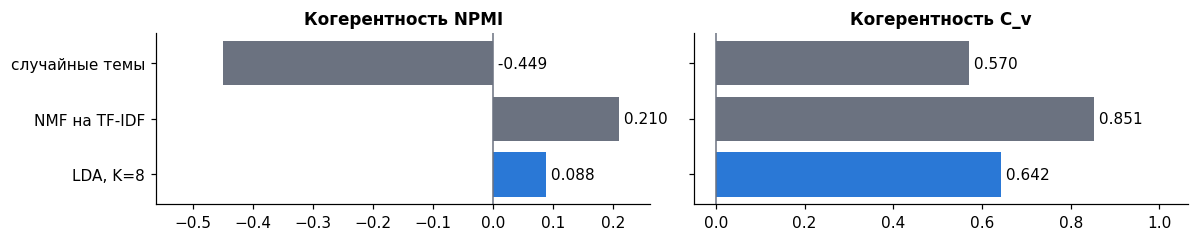

In [21]:
from sklearn.decomposition import NMF

rng = np.random.RandomState(SEED)
vocab_list = [dictionary[i] for i in range(len(dictionary))]
random_topics = [list(rng.choice(vocab_list, size=10, replace=False)) for _ in range(K_MAIN)]
nmf = NMF(n_components=K_MAIN, random_state=SEED, init="nndsvda", max_iter=300).fit(X_tfidf)
nmf_topics = [[dictionary[i] for i in np.argsort(c)[::-1][:10]] for c in nmf.components_]
lda_topics = [top_words(phi, k) for k in range(K_MAIN)]

rows_b = []
for name, tp in [("случайные темы", random_topics), ("NMF на TF-IDF", nmf_topics), (f"LDA, K={K_MAIN}", lda_topics)]:
    rows_b.append({"модель": name, "NPMI": coherence(tp).get_coherence(), "C_v": coherence(tp, "c_v").get_coherence()})
base_df = pd.DataFrame(rows_b).set_index("модель")
baseline_cv = base_df["NPMI"].to_dict()
display(base_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 2.3), sharey=True)
for ax, col in zip(axes, ["NPMI", "C_v"]):
    vals = base_df[col][::-1]
    ax.barh(vals.index, vals.values, color=[CAT[0], MUTED, MUTED])
    for i, v in enumerate(vals.values):
        ax.text(max(v, 0), i, f" {v:.3f}", va="center")
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlim(min(vals.min() * 1.25, -0.05), vals.max() * 1.25); ax.set_title(f"Когерентность {col}")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** По мере NPMI случайные темы получают отрицательное значение, LDA положительное: мера отличает осмысленные темы от шума. NMF на TF-IDF даёт на этом корпусе более связные главные слова, чем LDA. При этом NMF не даёт вероятностей: по нему нельзя посчитать перплексию и доли тем в документе в сумме не дают единицу.

Правая панель показывает ту же тройку по мере $C_v$, которая часто встречается в статьях и руководствах. Случайные наборы слов получают по ней значение, близкое к значению LDA. Мера $C_v$ сравнивает слова косвенно, через их окружение, и на наборах редких слов завышает оценку. Отсюда правило: значение любой меры качества сравнивают с точкой отсчёта, и для выбора модели здесь используется NPMI.

### Перебор числа тем

Модель обучается при нескольких значениях $K$, по три запуска на каждое значение. Для каждой модели считаются перплексия на обучающих и на отложенных документах и когерентность. Ячейка выполняется около минуты.

In [22]:
K_GRID = [2, 4, 8, 12, 20, 30]
GRID_SEEDS = (1, 2, 3)
grid = []
for k in K_GRID:
    for s in GRID_SEEDS:
        m = candidates[s] if k == K_MAIN else train_lda(k, seed=s)
        ph = get_phi(m)
        cm = coherence([top_words(ph, t) for t in range(k)])
        grid.append({"K": k, "seed": s, "phi": ph,
                     "ppl_train": perplexity(ph, fold_in(ph, N_train), N_train),
                     "ppl_test": completion_perplexity(ph, test_docs),
                     "npmi": cm.get_coherence(), "npmi_topics": cm.get_coherence_per_topic()})
        print(f"K={k:>2} seed={s}  перплексия: обучение {grid[-1]['ppl_train']:.0f}, отложенные {grid[-1]['ppl_test']:.0f}   NPMI={grid[-1]['npmi']:.3f}")
runs_df = pd.DataFrame([{k: v for k, v in g.items() if k not in ("phi", "npmi_topics")} for g in grid])
grid_df = runs_df.groupby("K", as_index=False)[["ppl_train", "ppl_test", "npmi"]].mean()
display(grid_df.round(3))

K= 2 seed=1  перплексия: обучение 1956, отложенные 2018   NPMI=0.059
K= 2 seed=2  перплексия: обучение 1965, отложенные 2018   NPMI=0.035
K= 2 seed=3  перплексия: обучение 1955, отложенные 2019   NPMI=0.059
K= 4 seed=1  перплексия: обучение 1530, отложенные 1682   NPMI=0.067
K= 4 seed=2  перплексия: обучение 1526, отложенные 1701   NPMI=0.070
K= 4 seed=3  перплексия: обучение 1674, отложенные 1845   NPMI=0.049
K= 8 seed=1  перплексия: обучение 1451, отложенные 1745   NPMI=0.064
K= 8 seed=2  перплексия: обучение 1414, отложенные 1722   NPMI=0.040
K= 8 seed=3  перплексия: обучение 1449, отложенные 1742   NPMI=0.071
K=12 seed=1  перплексия: обучение 1291, отложенные 1666   NPMI=0.084
K=12 seed=2  перплексия: обучение 1315, отложенные 1700   NPMI=0.011
K=12 seed=3  перплексия: обучение 1333, отложенные 1704   NPMI=0.008
K=20 seed=1  перплексия: обучение 1186, отложенные 1709   NPMI=0.037
K=20 seed=2  перплексия: обучение 1188, отложенные 1699   NPMI=0.009
K=20 seed=3  перплексия: обучение 

,K,ppl_train,ppl_test,npmi
0,2,1958.615,2018.432,0.051
1,4,1576.699,1742.607,0.062
2,8,1437.952,1736.480,0.058
3,12,1313.059,1690.232,0.034
4,20,1185.963,1706.139,0.019
5,30,1062.136,1710.024,-0.017


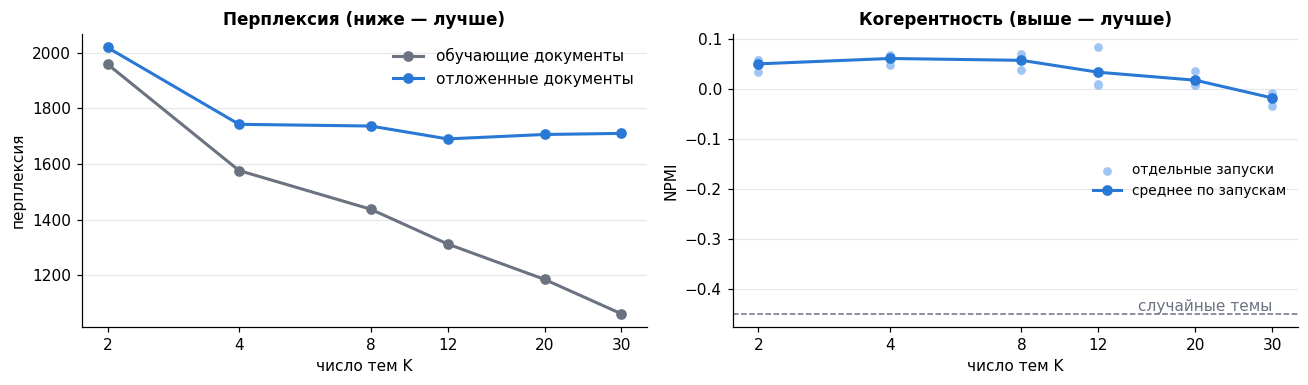

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ax.plot(grid_df.K, grid_df.ppl_train, color=MUTED, marker="o", lw=2, label="обучающие документы")
ax.plot(grid_df.K, grid_df.ppl_test, color=CAT[0], marker="o", lw=2, label="отложенные документы")
ax.set_ylabel("перплексия"); ax.set_title("Перплексия (ниже — лучше)"); ax.legend(frameon=False)
ax = axes[1]
ax.scatter(runs_df.K, runs_df.npmi, s=22, color="#9ec5f4", zorder=2, label="отдельные запуски")
ax.plot(grid_df.K, grid_df.npmi, color=CAT[0], marker="o", lw=2, label="среднее по запускам")
ax.axhline(baseline_cv["случайные темы"], color=MUTED, ls="--", lw=1)
ax.text(K_GRID[-1], baseline_cv["случайные темы"], "случайные темы", ha="right", va="bottom", color=MUTED)
ax.set_ylabel("NPMI"); ax.set_title("Когерентность (выше — лучше)"); ax.legend(frameon=False, fontsize=9)
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID); ax.minorticks_off()
    ax.set_xlabel("число тем K"); ax.grid(axis="y", color=GRID)
fig.tight_layout()
plt.show()

**Что видно на рисунке.** Перплексия на обучающих документах с ростом $K$ снижается: модель с большим числом параметров точнее описывает данные, на которых обучена. По этой кривой число тем выбрать нельзя. На отложенных документах улучшение прекращается раньше, и разрыв между кривыми растёт. Этот разрыв показывает переобучение. Когерентность ведёт себя иначе: с ростом $K$ она не увеличивается, при большом числе тем темы дробятся и становятся менее связными. Светлые точки показывают отдельные запуски. Разброс между запусками при одном $K$ сопоставим с различиями между соседними значениями $K$, поэтому по одному запуску число тем выбирать нельзя.

Число тем выбирают по совокупности признаков. Перплексия на отложенных документах перестала заметно улучшаться, когерентность высока, темы понятны при чтении. В блокноте взято $K=8$: по таблице выше видно, насколько этот выбор согласуется с обеими мерами.

### Когерентность отдельных тем

Среднее по темам скрывает разброс. В одной модели бывают и очень связные темы, и неудачные.

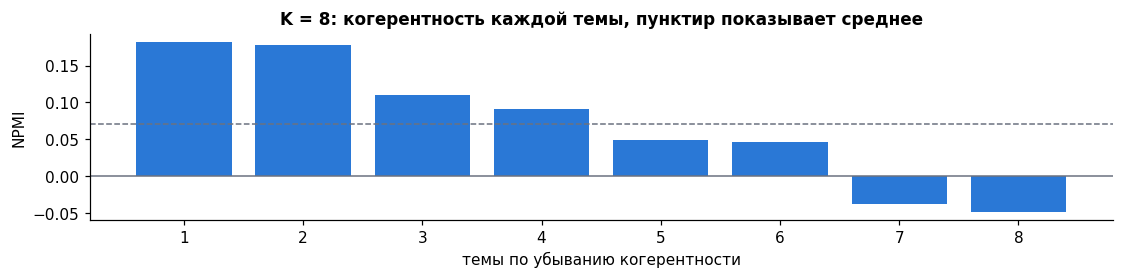

  лучшая тема  (0.18): матч, сборная, команда, чемпионат, клуб, счет, тренер, турнир
  худшая тема (-0.05): сша, компания, ученый, самолет, проект, американский, производство, исследование


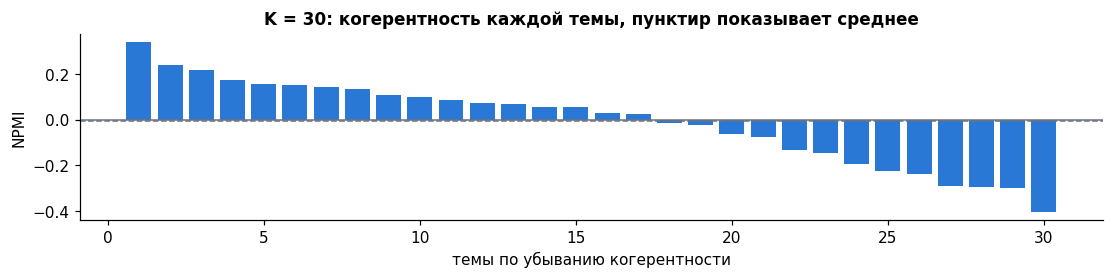

  лучшая тема  (0.34): космический, ракета, корабль, спутник, орбита, станция, запуск, мкс
  худшая тема (-0.40): нью, йорк, советский, перевод, голубой, краснодар, пошлина, сын


In [24]:
for k_show in (K_MAIN, 30):
    g = max((g for g in grid if g["K"] == k_show), key=lambda g: g["npmi"])
    order = np.argsort(g["npmi_topics"])[::-1]
    fig, ax = plt.subplots(figsize=(12, 2.2))
    ax.bar(range(1, k_show + 1), np.array(g["npmi_topics"])[order], color=CAT[0])
    ax.axhline(g["npmi"], color=MUTED, ls="--", lw=1); ax.axhline(0, color=MUTED, lw=1)
    ax.set_xlabel("темы по убыванию когерентности"); ax.set_ylabel("NPMI")
    ax.set_title(f"K = {k_show}: когерентность каждой темы, пунктир показывает среднее")
    plt.show()
    print(f"  лучшая тема  ({g['npmi_topics'][order[0]]:.2f}):", ", ".join(top_words(g["phi"], order[0], 8)))
    print(f"  худшая тема ({g['npmi_topics'][order[-1]]:.2f}):", ", ".join(top_words(g["phi"], order[-1], 8)))

## Часть 8. Регуляризация: разреживание тем

Подход ARTM добавляет к логарифму правдоподобия PLSA регуляризаторы. Обучение остаётся EM-алгоритмом, меняется только M-шаг. Регуляризатор разреживания вычитает из каждого счётчика $n_{wk}$ постоянную $\tau$, отрицательные значения заменяются нулём:

$$\phi_{wk}\;\propto\;\max(n_{wk}-\tau,\;0).$$

Слово, которое в теме встречается редко, получает в ней точный ноль. Тема становится короче. Ниже EM-алгоритм из части 1 переписан для разреженной матрицы и дополнен параметром `tau`. Полноценная работа с регуляризаторами в библиотеке BigARTM предстоит на семинаре 6.

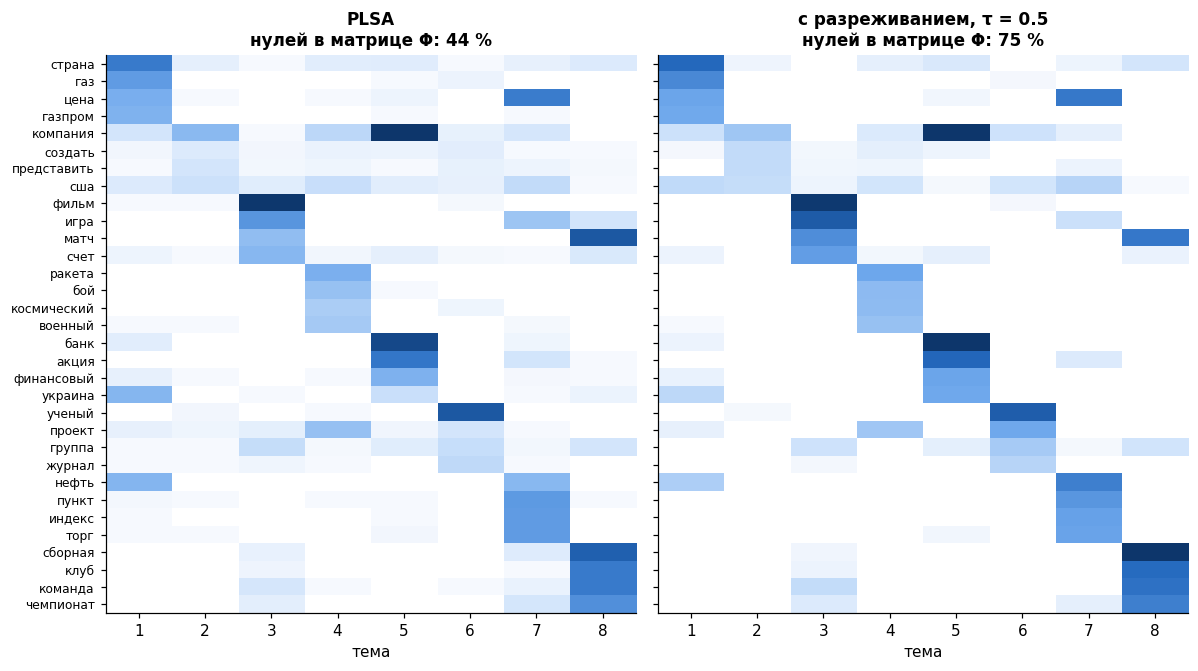

In [25]:
def em_artm(N, K, n_iter=40, tau=0.0, sparse_from=10, seed=SEED):
    # EM-алгоритм PLSA на разреженной матрице; при tau > 0 добавляется разреживание phi.
    rng = np.random.RandomState(seed)
    N = sp.coo_matrix(N)
    D, W = N.shape
    phi = rng.rand(K, W) + 0.01
    phi /= phi.sum(1, keepdims=True)
    theta = np.full((D, K), 1.0 / K)
    for it in range(n_iter):
        p = np.einsum("nk,nk->n", theta[N.row], phi.T[N.col]) + 1e-12       # p(w|d) для ненулевых клеток
        R = sp.csr_matrix((N.data / p, (N.row, N.col)), shape=(D, W))
        n_kw = phi * (R.T @ theta).T
        n_dk = theta * (R @ phi.T)
        if tau > 0 and it >= sparse_from:                                    # первые итерации идут без регуляризатора
            n_kw = np.maximum(n_kw - tau, 0.0)
        phi = n_kw / np.maximum(n_kw.sum(1, keepdims=True), 1e-12)
        theta = n_dk / n_dk.sum(1, keepdims=True)
    return phi, theta


phi_plsa, theta_plsa = em_artm(N_train, K_MAIN)
phi_sparse, theta_sparse = em_artm(N_train, K_MAIN, tau=0.5)

words = []
for k in range(K_MAIN):
    for i in np.argsort(phi_sparse[k])[::-1]:
        if i not in words:
            words.append(i)
        if len(words) == (k + 1) * 4:
            break
fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), sharey=True)
vmax = phi_sparse[:, words].max() * 0.6
for ax, ph, name in [(axes[0], phi_plsa, "PLSA"), (axes[1], phi_sparse, "с разреживанием, τ = 0.5")]:
    Mw = ph[:, words].T
    ax.imshow(np.where(Mw < 1e-12, np.nan, Mw), cmap=SEQ, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(K_MAIN)); ax.set_xticklabels(range(1, K_MAIN + 1)); ax.set_xlabel("тема")
    ax.set_yticks(range(len(words))); ax.set_yticklabels([dictionary[i] for i in words], fontsize=8)
    ax.set_title(f"{name}\nнулей в матрице Φ: {100 * (ph < 1e-12).mean():.0f} %")
fig.tight_layout()
plt.show()

,tau,"нулей в Φ, %",перплексия (обучение),NPMI
0,0.00,43.868,1271.747,0.049
1,0.10,66.707,1353.453,0.044
2,0.25,71.002,1386.204,0.041
3,0.50,74.930,1424.420,0.031
4,1.00,79.640,1484.070,0.042
5,2.00,83.785,1647.782,0.031


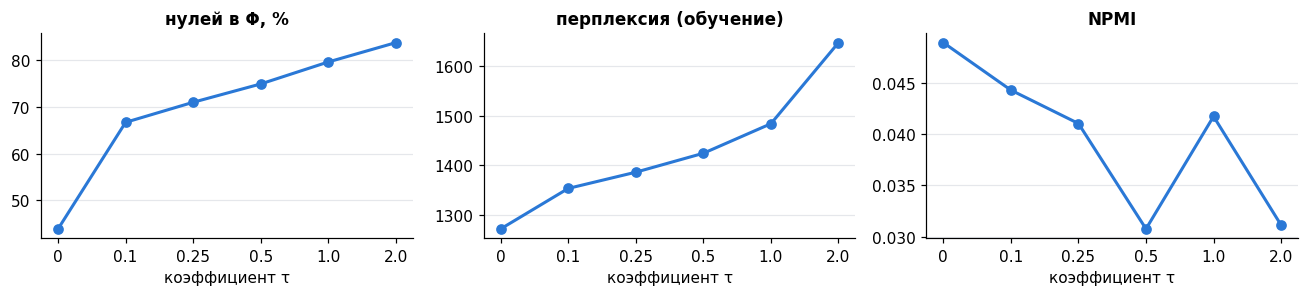

In [26]:
taus = [0, 0.1, 0.25, 0.5, 1.0, 2.0]
rows_tau = []
for t in taus:
    ph, th = (phi_plsa, theta_plsa) if t == 0 else em_artm(N_train, K_MAIN, tau=t)
    rows_tau.append({"tau": t, "нулей в Φ, %": 100 * (ph < 1e-12).mean(), "перплексия (обучение)": perplexity(ph, th, N_train),
                     "NPMI": coherence([top_words(ph, k) for k in range(K_MAIN)]).get_coherence()})
tau_df = pd.DataFrame(rows_tau)
display(tau_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, col in zip(axes, ["нулей в Φ, %", "перплексия (обучение)", "NPMI"]):
    ax.plot(range(len(taus)), tau_df[col], color=CAT[0], marker="o", lw=2)
    ax.set_xticks(range(len(taus))); ax.set_xticklabels(taus); ax.set_xlabel("коэффициент τ"); ax.set_title(col)
    ax.grid(axis="y", color=GRID)
fig.tight_layout()
plt.show()

**Что видно на рисунках.** Белая клетка тепловой карты означает точный ноль. В PLSA почти каждое слово имеет малую ненулевую вероятность в нескольких темах. После разреживания доля нулей в матрице $\Phi$ заметно выросла, и тема описывается коротким списком слов. Плата за это видна на среднем графике: с ростом $\tau$ перплексия увеличивается, потому что модель хуже описывает редкие слова. Коэффициент регуляризации подбирают так, чтобы потеря в правдоподобии оставалась приемлемой.

## Часть 9. Данные без текста: транзакции клиентов банка

Тематической модели нужны объекты, описанные наборами дискретных событий. Клиент банка играет роль документа, категория торговой точки (код MCC) играет роль слова. Тема в такой модели описывает тип потребительского поведения.

Реальные транзакции закрыты, поэтому данные синтетические. Заданы пять типов поведения, у каждого свой профиль трат по 12 категориям. Клиент получает случайную смесь типов из распределения Дирихле и совершает около 120 покупок. У синтетических данных есть преимущество: истинные профили известны, и можно проверить, восстановит ли их модель.

In [27]:
MCC = ["Супермаркеты", "АЗС", "Автозапчасти", "Рестораны", "Такси", "Развлечения", "Авиабилеты", "Отели",
       "Детские товары", "Аптеки", "Стройматериалы", "Электроника"]
TYPES = ["автомобиль", "городской досуг", "путешествия", "семья с детьми", "ремонт и дом"]


def make_transactions(n_clients=600, mean_purchases=120, alpha=0.25, seed=SEED):
    rng = np.random.RandomState(seed)
    base = np.full((len(TYPES), len(MCC)), 0.4)
    base[:, 0] = 3.0                                          # супермаркеты есть у всех типов
    for k, cats in {0: [1, 2], 1: [3, 4, 5], 2: [6, 7, 3], 3: [8, 9, 0], 4: [10, 11]}.items():
        base[k, cats] += 8                                    # характерные категории типа
    phi_true = base / base.sum(1, keepdims=True)
    theta_true = rng.dirichlet(np.full(len(TYPES), alpha), size=n_clients)
    X = np.zeros((n_clients, len(MCC)), dtype=int)
    for c in range(n_clients):
        z = rng.choice(len(TYPES), size=rng.poisson(mean_purchases), p=theta_true[c])
        for k in range(len(TYPES)):
            X[c] += rng.multinomial((z == k).sum(), phi_true[k])
    return X, phi_true, theta_true


X_tr, phi_true, theta_true = make_transactions()
print("Матрица «клиенты x категории»:", X_tr.shape, "| покупок всего:", X_tr.sum())
display(pd.DataFrame(X_tr[:5], columns=MCC, index=[f"клиент {i + 1}" for i in range(5)]))

Матрица «клиенты x категории»: (600, 12) | покупок всего: 72419


,Супермаркеты,АЗС,Автозапчасти,Рестораны,Такси,Развлечения,Авиабилеты,Отели,Детские товары,Аптеки,Стройматериалы,Электроника
клиент 1,11,3,1,21,17,24,0,5,1,1,9,10
клиент 2,11,2,0,36,38,29,2,0,1,3,9,3
клиент 3,14,13,17,7,1,4,4,9,5,4,14,18
клиент 4,13,2,1,28,31,32,4,4,3,5,2,1
клиент 5,24,4,1,3,2,1,2,3,2,3,40,35


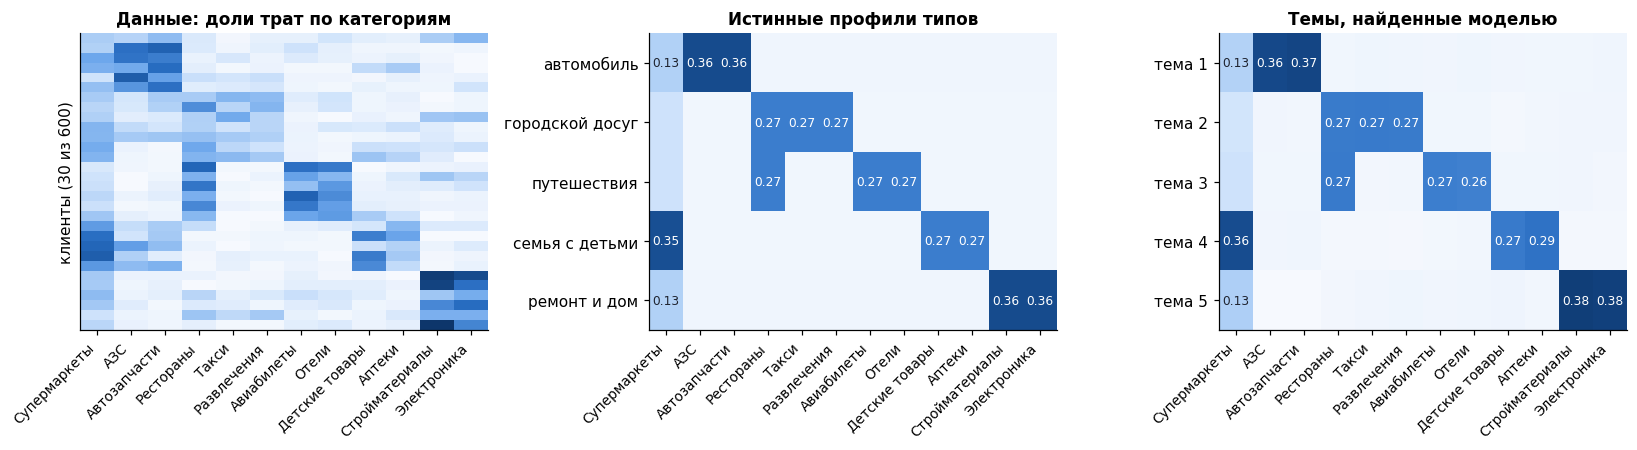

Косинусная близость истинных и найденных профилей: [1.    1.    1.    0.999 0.999]
Корреляция истинных и найденных долей у клиентов:   [0.99  0.986 0.987 0.987 0.989]


In [28]:
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import LatentDirichletAllocation

lda_tr = LatentDirichletAllocation(n_components=len(TYPES), random_state=SEED, max_iter=100,
                                   doc_topic_prior=0.25, topic_word_prior=0.1).fit(X_tr)
phi_tr = lda_tr.components_ / lda_tr.components_.sum(1, keepdims=True)
theta_tr = lda_tr.transform(X_tr)

# темы модели нумеруются произвольно: сопоставляем их с истинными типами по косинусной близости
cos = phi_true @ phi_tr.T / np.outer(np.linalg.norm(phi_true, axis=1), np.linalg.norm(phi_tr, axis=1))
_, match = linear_sum_assignment(-cos)
phi_tr, theta_tr = phi_tr[match], theta_tr[:, match]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
show = np.argsort(theta_true.argmax(1), kind="stable")[::20][:30]
axes[0].imshow(X_tr[show] / X_tr[show].sum(1, keepdims=True), cmap=SEQ, aspect="auto", vmin=0)
axes[0].set_yticks([]); axes[0].set_ylabel("клиенты (30 из 600)"); axes[0].set_title("Данные: доли трат по категориям")
for ax, ph, name in [(axes[1], phi_true, "Истинные профили типов"), (axes[2], phi_tr, "Темы, найденные моделью")]:
    ax.imshow(ph, cmap=SEQ, aspect="auto", vmin=0, vmax=0.4)
    ax.set_yticks(range(len(TYPES))); ax.set_yticklabels(TYPES if ax is axes[1] else [f"тема {k + 1}" for k in range(5)])
    for i in range(ph.shape[0]):
        for j in range(ph.shape[1]):
            if ph[i, j] >= 0.1:
                ax.text(j, i, f"{ph[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if ph[i, j] > 0.25 else "#1f2430")
    ax.set_title(name)
for ax in axes:
    ax.set_xticks(range(len(MCC))); ax.set_xticklabels(MCC, rotation=45, ha="right", fontsize=9)
fig.tight_layout()
plt.show()

print("Косинусная близость истинных и найденных профилей:", np.round(cos[np.arange(5), match], 3))
print("Корреляция истинных и найденных долей у клиентов:  ",
      np.round([np.corrcoef(theta_true[:, k], theta_tr[:, k])[0, 1] for k in range(5)], 3))

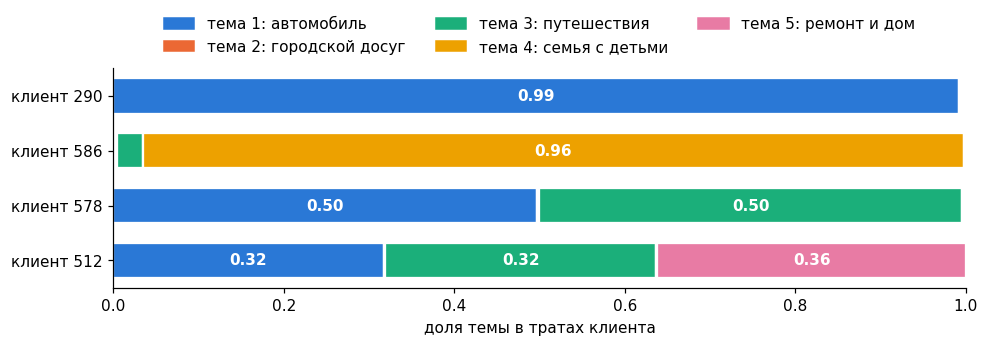

In [29]:
srt_tr = np.sort(theta_tr, axis=1)
clients = [int(np.argmax(theta_tr[:, 0])), int(np.argmax(theta_tr[:, 3])),
           int(np.argmax(np.minimum(srt_tr[:, -1], srt_tr[:, -2]))), int(np.argmax(srt_tr[:, -3]))]
fig, ax = plt.subplots(figsize=(10, 2.6))
for row, c in enumerate(clients[::-1]):
    left = 0
    for k in range(len(TYPES)):
        ax.barh(row, theta_tr[c, k], left=left, color=CAT[k], edgecolor="white", linewidth=1.5, height=0.65)
        if theta_tr[c, k] > 0.08:
            ax.text(left + theta_tr[c, k] / 2, row, f"{theta_tr[c, k]:.2f}", ha="center", va="center", color="white", fontweight="bold")
        left += theta_tr[c, k]
ax.set_yticks(range(len(clients))); ax.set_yticklabels([f"клиент {c + 1}" for c in clients[::-1]])
ax.set_xlim(0, 1); ax.set_xlabel("доля темы в тратах клиента")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=CAT[k]) for k in range(len(TYPES))], [f"тема {k + 1}: {TYPES[k]}" for k in range(5)],
          ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.show()

**Что видно на рисунках.** По исходной матрице долей трат типы поведения глазами не различить. Модель восстановила пять профилей почти точно: найденные темы совпадают с заданными, оценки долей у клиентов близки к истинным. Категория «Супермаркеты» присутствует во всех темах с заметной вероятностью, как общеупотребительное слово в текстах.

Вектор $\theta$ клиента служит компактным и понятным описанием его поведения. Такой вектор используют как признак в моделях оттока и кредитного риска и для сегментации клиентской базы. Изменение вектора во времени показывает смену поведения клиента.

В реальных данных число типов неизвестно, клиенты сильно различаются по числу покупок, а у категорий есть сумма и время. Суммы и время переводят в дискретные признаки, и модель описывает клиента несколькими видами «слов» одновременно. В подходе ARTM такие виды называются модальностями.

## Часть 10. Задания для самостоятельной работы

Заданий восемь. Задания 1–6 обязательные, задания 7 и 8 повышенной сложности. В каждом задании указан ожидаемый результат для самопроверки. Вывод по каждому заданию записывается одной-двумя фразами в отдельной ячейке: что получено и что это означает.

Все функции из разобранных частей доступны: `train_lda`, `get_phi`, `get_theta`, `model_coherence`, `top_words`, `plot_topics`, `plot_mixtures`, `fold_in`, `perplexity`, `completion_perplexity`, `coherence`, `em_artm`, `make_transactions`.

### Задание 1. Свойства распределения Дирихле

а) Выведите аналитически математическое ожидание $\mathbb{E}[\theta_k]$ для симметричного распределения $\mathrm{Dir}(\alpha,\dots,\alpha)$ с $K$ компонентами.

б) Проверьте результат численно: сгенерируйте 1000 векторов при $K=10$ для $\alpha\in\{0.1,\,1,\,10\}$ и сравните выборочное среднее с теоретическим.

в) Назовём компоненту заметной, если она больше 0.05. Для каждого $\alpha$ постройте гистограмму числа заметных компонент в векторе. Объясните, почему при одинаковом среднем векторы выглядят по-разному.

**Самопроверка.** Выборочные средние отличаются от $1/K=0.1$ не более чем на 0.02. Среднее число заметных компонент при $\alpha=0.1$ лежит между 1.5 и 3, при $\alpha=10$ оно больше 8.

In [30]:
# Задание 1. Ваш код:
# samples = np.random.RandomState(SEED).dirichlet([alpha] * 10, size=1000)

### Задание 2. Один шаг сэмплера Гиббса

Напишите функцию `gibbs_probs(n_dk, n_kw, n_k, alpha, beta, V)`, которая возвращает вероятности тем для одного слова по формуле из части 2. Аргументы: `n_dk` содержит числа слов документа по темам, `n_kw` числа назначений данного слова по темам, `n_k` общие числа слов тем, `V` размер словаря. Все счётчики заданы уже без текущего слова.

Проверьте функцию на примере из лекции: две темы, $\alpha=0.5$, $\beta=0.1$, словарь из 10 слов. В документе 4 слова отнесены к теме 1 и 2 слова к теме 2. Слово «банк» отнесено к теме 1 три раза из 40 слов темы и к теме 2 девять раз из 30.

Затем измените пример: пусть в документе 20 слов темы 1 и 2 слова темы 2. К какой теме теперь вероятнее отойдёт слово «банк»? Объясните результат через два множителя формулы.

**Самопроверка.** В исходном примере вероятности равны 0.317 и 0.683. В изменённом примере вероятность темы 1 становится больше 0.5.

In [31]:
# Задание 2. Ваш код:
# def gibbs_probs(n_dk, n_kw, n_k, alpha, beta, V):
#     ...

### Задание 3. Влияние предобработки

Обучите LDA с $K=8$ на том же корпусе в двух вариантах предобработки и сравните с основной моделью.

а) Без лемматизации: `preprocess(text, lemmatize=False)`.

б) Без дополнительного списка стоп-слов `EXTRA_STOP` (лемматизация включена).

Для каждого варианта постройте свой словарь с теми же порогами фильтрации, обучите модель и выведите размер словаря, главные слова тем и когерентность NPMI. Когерентность считается на текстах того же варианта: `CoherenceModel(topics=..., texts=..., dictionary=..., coherence="c_npmi")`.

**Самопроверка.** Словарь без лемматизации больше лемматизированного не менее чем на 20 %, и в темах встречаются разные формы одного слова («банк», «банка»). В варианте (б) в главных словах нескольких тем появляются слова из `EXTRA_STOP`. Сделайте вывод, можно ли сравнивать значения когерентности между вариантами с разными словарями.

In [32]:
# Задание 3. Ваш код:
# docs_raw = [preprocess(title + ". " + text, lemmatize=False) for title, text in zip(titles, texts)]

### Задание 4. Выбор числа тем и разброс между запусками

а) Дополните перебор из части 7 значением $K=50$. Постройте оба графика заново.

б) Для $K=8$ обучите модель с пятью разными значениями `seed` и посчитайте NPMI и перплексию на отложенных документах для каждого запуска. Нанесите разброс (минимум, среднее, максимум) на график когерентности.

в) Сравните разброс между запусками с разницей в когерентности между соседними значениями $K$. Какие различия между значениями $K$ на графике значимы, а какие сопоставимы с разбросом?

**Самопроверка.** Разрыв между перплексией на отложенных и на обучающих документах при $K=50$ больше, чем при $K=8$. Когерентность при $K=50$ ниже максимальной по сетке. Размах NPMI между пятью запусками сопоставим с разницей между соседними значениями $K$.

In [33]:
# Задание 4. Ваш код:
# seed_models = [train_lda(8, seed=s) for s in (11, 12, 13, 14, 15)]

### Задание 5. Устойчивость тем

Обучите две модели с $K=8$ и разными `seed`. Темы в них пронумерованы по-разному, поэтому сначала их нужно сопоставить.

а) Посчитайте матрицу косинусной близости между строками $\Phi$ первой и второй модели и покажите её тепловой картой.

б) Найдите наилучшее взаимно однозначное сопоставление тем функцией `scipy.optimize.linear_sum_assignment` (пример есть в части 9). Переставьте темы второй модели и покажите тепловую карту ещё раз.

в) Тему считаем устойчивой, если близость с её парой больше 0.7. Сколько тем устойчивы? Выведите главные слова устойчивых и неустойчивых тем.

**Самопроверка.** После перестановки наибольшие значения стоят на диагонали. Устойчивыми оказываются не менее двух тем из восьми. Сформулируйте вывод: каким темам модели можно доверять.

In [34]:
# Задание 5. Ваш код:

### Задание 6. Пограничный документ

Найдите в обучающей части документы, у которых две темы имеют близкие доли: обе доли больше 0.3 и отличаются меньше чем на 0.05. Сколько таких документов?

Для трёх из них выведите заголовок, профиль тем (функция `plot_mixtures`) и раскраску слов (функция `color_document`). Прочитайте тексты и объясните, почему документ находится на границе двух тем. Сравните темы модели с редакционной рубрикой документа.

**Самопроверка.** Таких документов находится не менее десяти. Если их меньше, ослабьте условие и укажите новое значение порога.

In [35]:
# Задание 6. Ваш код:

### Задание 7 (повышенной сложности). Число типов поведения клиентов

В части 9 число тем было известно заранее. Проверьте, можно ли найти его по данным.

а) Разделите клиентов на обучающих (500) и отложенных (100). Для $K=2,\dots,9$ обучите `LatentDirichletAllocation` и посчитайте перплексию на отложенных клиентах по схеме «дополнение документа». Подсказка: покупки клиента случайно делятся пополам функцией `np.random.binomial(X, 0.5)`, затем применяются `fold_in` и `perplexity` из части 7.

б) Постройте график перплексии от $K$. При каком $K$ кривая выходит на плато?

в) Повторите опыт для клиентов с малым числом покупок: `make_transactions(mean_purchases=15)`. Как изменилась кривая и точность восстановления профилей?

**Самопроверка.** При 120 покупках перплексия заметно падает до $K=5$ и дальше почти не меняется. При 15 покупках наименьшая перплексия достигается при меньшем $K$, и корреляция истинных и найденных долей опускается примерно до 0.9. Объясните, почему короткие «документы» не позволяют различить все пять типов.

In [36]:
# Задание 7. Ваш код:

### Задание 8 (повышенной сложности). Регуляризатор декоррелирования

Регуляризатор декоррелирования уменьшает счётчик слова в теме, если это слово вероятно и в других темах. M-шаг для $\Phi$ принимает вид

$$\phi_{wk}\;\propto\;\max\Big(n_{wk}-\tau\,\phi_{wk}\sum_{s\ne k}\phi_{ws},\;0\Big).$$

а) Добавьте этот регуляризатор в функцию `em_artm` отдельным параметром `tau_decor`.

б) Обучите модели с $K=8$ при `tau_decor` из набора $\{0,\;10^{4},\;10^{5},\;10^{6}\}$. Для каждой посчитайте среднюю косинусную близость между парами тем, перплексию на обучающих документах и NPMI.

в) Постройте тепловые карты близости тем для модели без регуляризатора и для модели с наибольшим коэффициентом.

**Самопроверка.** Средняя близость между темами убывает с ростом `tau_decor`: примерно с 0.21 без регуляризатора до 0.09 при $10^{6}$. Перплексия до $10^{5}$ почти не меняется и заметно растёт при $10^{6}$. Объясните, почему рабочие значения коэффициента так велики: сравните порядок величины произведения $\phi_{wk}\sum_s\phi_{ws}$ с порядком счётчиков $n_{wk}$.

In [37]:
# Задание 8. Ваш код:

## Чек-лист

- [ ] Отложенные документы не участвуют в построении словаря и в обучении модели.
- [ ] Число тем выбрано по перплексии на отложенных документах и когерентности, перплексия на обучающих документах для выбора не используется.
- [ ] Когерентность считается мерой NPMI и сравнивается с точкой отсчёта: случайными темами и NMF.
- [ ] Значение `seed` зафиксировано во всех случайных шагах, результат воспроизводится при повторном запуске.
- [ ] Названия темам даны после чтения главных слов и документов с наибольшей долей темы.
- [ ] Выводы об отдельных темах проверены на нескольких запусках с разными `seed`.
- [ ] По каждому заданию записан вывод и результат сопоставлен с самопроверкой.

## Что дальше

Семинар 6 посвящён библиотеке BigARTM и методу BERTopic: регуляризаторы, модальности, темы на основе эмбеддингов. В домашнем задании 1 воспроизводится статья Griffiths и Steyvers (2004): собственный сэмплер Гиббса для LDA на полном корпусе, сравнение с gensim и тематическая карта корпуса для итогового проекта.